In [1]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=edc27ad26db089222ab2a9ccac168dddd13d0e6e308406a8b7de09c3834e0689
  Stored in directory: /root/.cache/pip/wheels/05/bd/e2/0c0eecf3c26b6cdb231b5656d53905bddc8090d69619d57e6b
Successfully built grad-cam


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import cv2
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms, models
from torch.optim.lr_scheduler import ReduceLROnPlateau, StepLR

# TensorBoard
from torch.utils.tensorboard import SummaryWriter

# Grad-CAM
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Sklearn
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Settings
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using: {device}')

# Metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    cohen_kappa_score
)

import torch.nn.functional as F

SEED = 4747
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

2026-09-06 09:49:19.328792: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1788688159.588469      56 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1788688159.674198      56 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1788688160.277235      56 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1788688160.277304      56 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1788688160.277307      56 computation_placer.cc:177] computation placer alr

Using: cuda


2. Exploratory Data Analysis (EDA)

In [3]:

TRAIN_DIR = '/kaggle/input/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/train'
TEST_DIR = '/kaggle/input/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/test'
VAL_DIR = '/kaggle/input/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/val'

def analyze_dataset(data_dir):
    class_counts = {}
    total_images = 0
    image_sizes = []
    
    for class_name in os.listdir(data_dir):
        class_path = os.path.join(data_dir, class_name)
        if os.path.isdir(class_path):
            images = os.listdir(class_path)
            class_counts[class_name] = len(images)
            total_images += len(images)
            
            for img_name in images[:10]:
                img_path = os.path.join(class_path, img_name)
                try:
                    img = Image.open(img_path)
                    image_sizes.append(img.size)
                except:
                    pass
    
    return class_counts, total_images, image_sizes

# train, val, test
train_counts, train_total, train_sizes = analyze_dataset(TRAIN_DIR)
val_counts, val_total, val_sizes = analyze_dataset(VAL_DIR)
test_counts, test_total, test_sizes = analyze_dataset(TEST_DIR)

print("Datasets analysis")
print(f"\nTrain: {train_total} images")
print(f"Validation: {val_total} images")
print(f"Test: {test_total} images")
print(f"Total: {train_total + val_total + test_total} images\n")

Datasets analysis

Train: 5778 images
Validation: 826 images
Test: 1656 images
Total: 8260 images



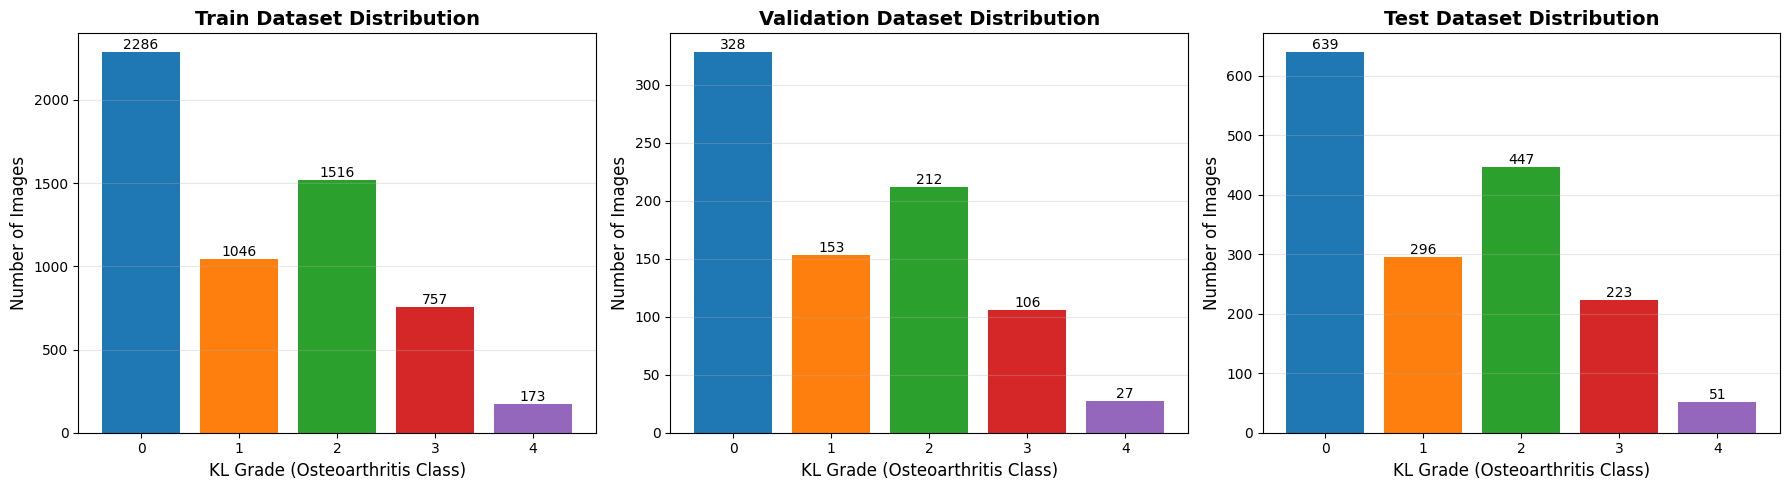


Class distribution in the training set:
Class 0: 2286 (39.6%)
Class 1: 1046 (18.1%)
Class 2: 1516 (26.2%)
Class 3: 757 (13.1%)
Class 4: 173 (3.0%)

Imbalance Ratio: 13.21
Significant class imbalance detected! Using WeightedRandomSampler or data augmentation is recommended.


In [4]:
# Visualize class distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

datasets_info = [
    ('Train', train_counts),
    ('Validation', val_counts),
    ('Test', test_counts)
]

for ax, (title, counts) in zip(axes, datasets_info):
    classes = sorted(counts.keys())
    values = [counts[c] for c in classes]
    
    bars = ax.bar(classes, values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'])
    ax.set_title(f'{title} Dataset Distribution', fontsize=14, fontweight='bold')
    ax.set_xlabel('KL Grade (Osteoarthritis Class)', fontsize=12)
    ax.set_ylabel('Number of Images', fontsize=12)
    ax.grid(axis='y', alpha=0.3)
    
    # Add value labels on top of bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height)}',
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Check for class imbalance
print("\nClass distribution in the training set:")
for class_name, count in sorted(train_counts.items()):
    percentage = (count / train_total) * 100
    print(f"Class {class_name}: {count} ({percentage:.1f}%)")

# Determine if balancing is necessary
max_count = max(train_counts.values())
min_count = min(train_counts.values())
imbalance_ratio = max_count / min_count
print(f"\nImbalance Ratio: {imbalance_ratio:.2f}")

if imbalance_ratio > 2:
    print("Significant class imbalance detected! Using WeightedRandomSampler or data augmentation is recommended.")
else:
    print("The dataset is relatively balanced.")

In [5]:
# Image size analysis
all_sizes = train_sizes + val_sizes + test_sizes
widths = [s[0] for s in all_sizes]
heights = [s[1] for s in all_sizes]

print("IMAGE SIZE ANALYSIS")
print(f"Mean width: {np.mean(widths):.0f} px")
print(f"Mean height: {np.mean(heights):.0f} px")
print(f"Min. size: {min(widths)}x{min(heights)} px")
print(f"Max. size: {max(widths)}x{max(heights)} px")
print(f"Most common size: {Counter(all_sizes).most_common(1)[0][0]}")

IMAGE SIZE ANALYSIS
Mean width: 224 px
Mean height: 224 px
Min. size: 224x224 px
Max. size: 224x224 px
Most common size: (224, 224)


In [6]:
# # Image sizes

# def get_image_sizes(data_dir):
#     sizes = []

#     for class_name in sorted(os.listdir(data_dir)):
#         class_path = os.path.join(data_dir, class_name)

#         if not os.path.isdir(class_path):
#             continue

#         for img_name in os.listdir(class_path):
#             img_path = os.path.join(class_path, img_name)

#             try:
#                 with Image.open(img_path) as img:
#                     sizes.append(img.size)
#             except Exception as e:
#                 print(f"Error reading {img_path}: {e}")

#     return sizes


# train_sizes = get_image_sizes(TRAIN_DIR)

# size_counts = Counter(train_sizes)

# print("Unique image sizes:")
# for size, count in size_counts.items():
#     print(size, count)

In [7]:
# # Visualization of samples from each class
# fig, axes = plt.subplots(5, 5, figsize=(15, 15))
# fig.suptitle('Sample Images from Each Class (KL Grade 0-4)', fontsize=16, fontweight='bold')

# for class_idx in range(5):
#     class_dir = os.path.join(TRAIN_DIR, str(class_idx))
#     images = os.listdir(class_dir)[:5]
    
#     for img_idx, img_name in enumerate(images):
#         img_path = os.path.join(class_dir, img_name)
#         img = Image.open(img_path)
        
#         ax = axes[class_idx, img_idx]
#         ax.imshow(img, cmap='gray')
#         ax.axis('on')
        
#         # Adding class labels for the first image in each row
#         if img_idx == 0:
#             ax.set_ylabel(f'KL Grade {class_idx}', fontsize=12, fontweight='bold')

# plt.tight_layout()
# plt.savefig('sample_images.png', dpi=300, bbox_inches='tight')
# plt.show()

In [8]:
# def analyze_brightness_contrast(data_dir):
#     records = []

#     for class_name in sorted(os.listdir(data_dir)):
#         class_path = os.path.join(data_dir, class_name)

#         if not os.path.isdir(class_path):
#             continue

#         for img_name in os.listdir(class_path):
#             img_path = os.path.join(class_path, img_name)

#             try:
#                 img = Image.open(img_path).convert("L")
#                 arr = np.array(img, dtype=np.float32)

#                 records.append({
#                     "class": int(class_name),
#                     "image": img_name,
#                     "mean_intensity": arr.mean(),
#                     "std_intensity": arr.std()
#                 })

#             except Exception as e:
#                 print(f"Error reading {img_path}: {e}")

#     return pd.DataFrame(records)


# stats_df = analyze_brightness_contrast(TRAIN_DIR)

# print(stats_df.groupby("class")[["mean_intensity", "std_intensity"]].agg(
#     ["mean", "std", "min", "max"]
# ))

In [9]:
# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# stats_df.boxplot(column="mean_intensity", by="class", ax=axes[0])
# axes[0].set_title("Brightness by KL Grade")
# axes[0].set_xlabel("KL Grade")
# axes[0].set_ylabel("Mean pixel intensity")

# stats_df.boxplot(column="std_intensity", by="class", ax=axes[1])
# axes[1].set_title("Contrast by KL Grade")
# axes[1].set_xlabel("KL Grade")
# axes[1].set_ylabel("Pixel intensity std")

# plt.suptitle("")
# plt.tight_layout()
# plt.show()

In [10]:
# balanced_stats = (
#     stats_df
#     .groupby("class", group_keys=False)
#     .sample(n=150, random_state=42)
# )

# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# balanced_stats.boxplot(
#     column="mean_intensity",
#     by="class",
#     ax=axes[0]
# )
# axes[0].set_title("Brightness by KL Grade")
# axes[0].set_xlabel("KL Grade")
# axes[0].set_ylabel("Mean pixel intensity")

# balanced_stats.boxplot(
#     column="std_intensity",
#     by="class",
#     ax=axes[1]
# )
# axes[1].set_title("Contrast by KL Grade")
# axes[1].set_xlabel("KL Grade")
# axes[1].set_ylabel("Pixel intensity std")

# plt.suptitle("")
# plt.tight_layout()
# plt.show()

### Searching for duplicates

In [11]:
# import hashlib

# def get_image_hashes(data_dir, split_name):
#     records = []

#     for class_name in sorted(os.listdir(data_dir)):
#         class_path = os.path.join(data_dir, class_name)

#         if not os.path.isdir(class_path):
#             continue

#         for img_name in os.listdir(class_path):
#             img_path = os.path.join(class_path, img_name)

#             try:
#                 with open(img_path, "rb") as f:
#                     file_hash = hashlib.md5(f.read()).hexdigest()

#                 records.append({
#                     "split": split_name,
#                     "class": class_name,
#                     "image": img_name,
#                     "path": img_path,
#                     "hash": file_hash
#                 })

#             except Exception as e:
#                 print(e)

#     return records


# all_hashes = (
#     get_image_hashes(TRAIN_DIR, "train")
#     + get_image_hashes(VAL_DIR, "val")
#     + get_image_hashes(TEST_DIR, "test")
# )

# hash_df = pd.DataFrame(all_hashes)

# duplicates = hash_df[hash_df.duplicated("hash", keep=False)].sort_values("hash")

# print(f"Duplicate image entries: {len(duplicates)}")
# display(duplicates)

### EDA Conclusions

Based on the exploratory dataset analysis:

1. **Dataset size:** The number of available images is sufficient for transfer learning and fine-tuning experiments.
2. **Class imbalance:** The dataset is strongly imbalanced, especially for KL Grade 4, so class weighting, sampling, or augmentation should be considered during training.
3. **Image characteristics:** Images have a consistent size of 224 × 224 pixels. Brightness and contrast distributions largely overlap across KL grades, although several outliers are present.
4. **Data integrity:** No exact duplicates were detected across the train, validation, and test splits.

## Data preparation and augumentation

In [12]:
import numpy as np
import torch

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, WeightedRandomSampler


# Parameters
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 5


# Transformations

# Training set transformations with mild augmentation
train_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomRotation(7),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05)
    ),

    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Validation/test: no augmentation
val_test_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Datasets

train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transforms
)

val_dataset = datasets.ImageFolder(
    root=VAL_DIR,
    transform=val_test_transforms
)

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=val_test_transforms
)


print(f"Training set: {len(train_dataset)} images")
print(f"Validation set: {len(val_dataset)} images")
print(f"Test set: {len(test_dataset)} images")
print(f"Classes: {train_dataset.class_to_idx}")


# WeightedRandomSampler

targets = np.array(train_dataset.targets)

class_counts = np.bincount(targets)

# Inverse frequency
class_weights = 1.0 / np.sqrt(class_counts)

# Weight for every training image
sample_weights = class_weights[targets]

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(
        sample_weights,
        dtype=torch.double
    ),
    num_samples=len(train_dataset),
    replacement=True
)


print("\nOriginal class distribution:")
for class_idx, count in enumerate(class_counts):
    print(f"KL {class_idx}: {count}")

print("\nClass sampling weights:")
for class_idx, weight in enumerate(class_weights):
    print(f"KL {class_idx}: {weight:.6f}")


# DataLoaders

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

Training set: 5778 images
Validation set: 826 images
Test set: 1656 images
Classes: {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4}

Original class distribution:
KL 0: 2286
KL 1: 1046
KL 2: 1516
KL 3: 757
KL 4: 173

Class sampling weights:
KL 0: 0.020915
KL 1: 0.030920
KL 2: 0.025683
KL 3: 0.036346
KL 4: 0.076029


# WandB initialization

In [13]:
!pip install -q wandb

In [14]:
import wandb

In [15]:
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
wandb_api_key = user_secrets.get_secret("WANDB_API_KEY")

wandb.login(key=wandb_api_key)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: kkaterynabilyk (kkaterynabilyk-lviv-polytechnic-national-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [16]:
PROJECT_NAME = "knee-xai"

In [ ]:
# Config example:
# config = {
#     "architecture": "resnet50",
#     "pretrained": "imagenet",
#     "img_size": 224,
#     "num_classes": 5,

#     "epochs": 20,
#     "batch_size": 32,

#     "optimizer": "adamw",
#     "learning_rate": 1e-4,
#     "weight_decay": 1e-4,

#     "loss": "cross_entropy",

#     "sampler": "weighted_random_sampler",

#     "augmentation": {
#         "rotation": 7,
#         "horizontal_flip": 0.5,
#         "translation": 0.05,
#         "brightness": 0.1,
#         "contrast": 0.1
#     },

#     "seed": 42
# }

# run = wandb.init(
#     project=PROJECT_NAME,
#     name="resnet50_ce_sampler",
#     config=config
# )

In [ ]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100.0 * correct / total

    return epoch_loss, epoch_acc

In [ ]:
def validate(model, loader, criterion, device, num_classes=5):
    model.eval()

    running_loss = 0.0

    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = F.softmax(outputs, dim=1)
            predicted = torch.argmax(outputs, dim=1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    epoch_loss = running_loss / len(loader)

    # Main metrics
    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    balanced_accuracy = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    # Macro metrics: every class has equal importance
    precision_macro = precision_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    # Weighted metrics: useful as additional information
    precision_weighted = precision_score(
        all_labels,
        all_preds,
        average="weighted",
        zero_division=0
    )

    recall_weighted = recall_score(
        all_labels,
        all_preds,
        average="weighted",
        zero_division=0
    )

    f1_weighted = f1_score(
        all_labels,
        all_preds,
        average="weighted",
        zero_division=0
    )

    # Per-class metrics
    precision_per_class = precision_score(
        all_labels,
        all_preds,
        labels=list(range(num_classes)),
        average=None,
        zero_division=0
    )

    recall_per_class = recall_score(
        all_labels,
        all_preds,
        labels=list(range(num_classes)),
        average=None,
        zero_division=0
    )

    f1_per_class = f1_score(
        all_labels,
        all_preds,
        labels=list(range(num_classes)),
        average=None,
        zero_division=0
    )

    # Quadratic Weighted Kappa
    qwk = cohen_kappa_score(
        all_labels,
        all_preds,
        weights="quadratic"
    )

    # Multiclass ROC-AUC
    try:
        auc = roc_auc_score(
            all_labels,
            all_probs,
            multi_class="ovr",
            average="weighted"
        )
    except ValueError:
        auc = 0.0

    metrics = {
        "loss": epoch_loss,

        "accuracy": accuracy * 100,
        "balanced_accuracy": balanced_accuracy * 100,

        "precision_macro": precision_macro * 100,
        "recall_macro": recall_macro * 100,
        "f1_macro": f1_macro * 100,

        "precision_weighted": precision_weighted * 100,
        "recall_weighted": recall_weighted * 100,
        "f1_weighted": f1_weighted * 100,

        "auc": auc,
        "qwk": qwk
    }

    # Add per-class metrics
    for class_idx in range(num_classes):
        metrics[f"precision_KL{class_idx}"] = (
            precision_per_class[class_idx] * 100
        )

        metrics[f"recall_KL{class_idx}"] = (
            recall_per_class[class_idx] * 100
        )

        metrics[f"f1_KL{class_idx}"] = (
            f1_per_class[class_idx] * 100
        )

    return metrics, all_preds, all_labels, all_probs

# ResNet with transfer learning

In [ ]:
from torchvision.models import ResNet50_Weights


def create_resnet50_model(
    num_classes=5,
    freeze_backbone=True
):
    """
    Resnet 50 creation with pretrained weights
    """
    weights = ResNet50_Weights.DEFAULT

    model = models.resnet50(weights=weights)

    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False

    num_features = model.fc.in_features

    model.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes)
    )

    return model

In [ ]:
resnet_model = create_resnet50_model(num_classes=NUM_CLASSES, freeze_backbone=True)
resnet_model = resnet_model.to(device)

# Display model information
total_params = sum(p.numel() for p in resnet_model.parameters())
trainable_params = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)

print(f"\nResulting ResNet50 Model:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

## ResNet50 Phase 1: head only

In [ ]:
config_resnet_headonly = {
    "model_name": "resnet50_head_only",
    "architecture": "resnet50",
    "training_stage": "head_only",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": True,

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 15,
    "optimizer": "adam",
    "learning_rate": 1e-3,

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="resnet50_head_only_ce_sampler",
    config=config_resnet_headonly,
    tags=[
        "resnet50",
        "head-only",
        "imagenet",
        "cross-entropy",
        "weighted-sampler"
    ]
)

In [ ]:
# 1. Model
resnet_model = create_resnet50_model(
    num_classes=NUM_CLASSES,
    freeze_backbone=True
).to(device)

# 2. Loss
criterion = nn.CrossEntropyLoss()

# 3. Optimizer
optimizer_phase1 = optim.Adam(
    resnet_model.fc.parameters(),
    lr=config_resnet_headonly["learning_rate"]
)

# 4. Scheduler
scheduler_phase1 = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
best_val_f1 = 0.0
best_epoch = 0

best_model_path = "resnet50_head_only_best.pth"

for epoch in range(config_resnet_headonly["epochs"]):

    # =====================
    # Train
    # =====================

    train_loss, train_acc = train_epoch(
        resnet_model,
        train_loader,
        criterion,
        optimizer_phase1,
        device
    )

    # =====================
    # Validation
    # =====================

    val_metrics, val_preds, val_labels, val_probs = validate(
        resnet_model,
        val_loader,
        criterion,
        device,
        num_classes=NUM_CLASSES
    )

    # Current LR
    current_lr = optimizer_phase1.param_groups[0]["lr"]

    # =====================
    # W&B logging
    # =====================

    log_data = {
        "epoch": epoch + 1,

        "train/loss": train_loss,
        "train/accuracy": train_acc,

        "val/loss": val_metrics["loss"],
        "val/accuracy": val_metrics["accuracy"],
        "val/balanced_accuracy": val_metrics["balanced_accuracy"],

        "val/precision_macro": val_metrics["precision_macro"],
        "val/recall_macro": val_metrics["recall_macro"],
        "val/f1_macro": val_metrics["f1_macro"],

        "val/precision_weighted": val_metrics["precision_weighted"],
        "val/recall_weighted": val_metrics["recall_weighted"],
        "val/f1_weighted": val_metrics["f1_weighted"],

        "val/auc_ovr": val_metrics["auc"],
        "val/qwk": val_metrics["qwk"],

        "learning_rate": current_lr
    }

    # Per-class metrics
    for class_idx in range(NUM_CLASSES):
        log_data[f"val/precision_KL{class_idx}"] = (
            val_metrics[f"precision_KL{class_idx}"]
        )

        log_data[f"val/recall_KL{class_idx}"] = (
            val_metrics[f"recall_KL{class_idx}"]
        )

        log_data[f"val/f1_KL{class_idx}"] = (
            val_metrics[f"f1_KL{class_idx}"]
        )

    run.log(log_data)

    # =====================
    # Scheduler
    # =====================

    scheduler_phase1.step(
        val_metrics["loss"]
    )

    # =====================
    # Save best checkpoint
    # =====================

    if val_metrics["f1_macro"] > best_val_f1:

        best_val_f1 = val_metrics["f1_macro"]
        best_epoch = epoch + 1

        checkpoint = {
            "epoch": best_epoch,

            "model_name":
                config_resnet_headonly["model_name"],

            "architecture":
                config_resnet_headonly["architecture"],

            "training_stage":
                config_resnet_headonly["training_stage"],

            "pretraining_source":
                config_resnet_headonly["pretraining_source"],

            "parent_model":
                config_resnet_headonly["parent_model"],

            "parent_run_id":
                config_resnet_headonly["parent_run_id"],

            "model_state_dict":
                resnet_model.state_dict(),

            "optimizer_state_dict":
                optimizer_phase1.state_dict(),

            "val_macro_f1":
                best_val_f1,

            "val_qwk":
                val_metrics["qwk"],

            "val_balanced_accuracy":
                val_metrics["balanced_accuracy"],

            "config":
                config_resnet_headonly
        }

        torch.save(
            checkpoint,
            best_model_path
        )

        print(
            f"✓ Best model saved "
            f"(Epoch {best_epoch}) "
            f"Macro F1: {best_val_f1:.2f}%"
        )

    # =====================
    # Console output
    # =====================

    print(
        f"Epoch {epoch + 1}/"
        f"{config_resnet_headonly['epochs']}"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Acc: {train_acc:.2f}%"
    )

    print(
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Acc: {val_metrics['accuracy']:.2f}% | "
        f"Balanced Acc: "
        f"{val_metrics['balanced_accuracy']:.2f}%"
    )

    print(
        f"Macro F1: {val_metrics['f1_macro']:.2f}% | "
        f"QWK: {val_metrics['qwk']:.4f}"
    )

    print("-" * 60)

In [ ]:
run.summary["best_epoch"] = best_epoch
run.summary["best_val_f1_macro"] = best_val_f1
run.summary["best_model_path"] = best_model_path

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

resnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_val_metrics, best_preds, best_labels, best_probs = validate(
    resnet_model,
    val_loader,
    criterion,
    device,
    num_classes=NUM_CLASSES
)

run.log({
    "val/confusion_matrix":
        wandb.plot.confusion_matrix(
            y_true=best_labels,
            preds=best_preds,
            class_names=[
                "KL0",
                "KL1",
                "KL2",
                "KL3",
                "KL4"
            ]
        )
})

In [ ]:
model_artifact = wandb.Artifact(
    name="resnet50_head_only",
    type="model",
    metadata={
        "architecture":
            config_resnet_headonly["architecture"],

        "training_stage":
            config_resnet_headonly["training_stage"],

        "pretraining_source":
            config_resnet_headonly["pretraining_source"],

        "parent_model":
            config_resnet_headonly["parent_model"],

        "parent_run_id":
            config_resnet_headonly["parent_run_id"],

        "best_epoch":
            best_epoch,

        "best_val_f1_macro":
            best_val_f1
    }
)

model_artifact.add_file(
    "/kaggle/working/resnet50_head_only_best.pth"
)

run.log_artifact(
    model_artifact,
    aliases=["best"]
)

In [ ]:
run.finish()

## ResNet50 Phase 2: fine-tuning

In [ ]:
config_resnet_finetune_layer3_4 = {
    "model_name": "resnet50_finetune_layer3_4",
    "architecture": "resnet50",
    "training_stage": "finetune_layer3_4",

    "pretraining_source": "custom_checkpoint",
    "parent_model": "resnet50_head_only",
    "parent_run_id": "ogsbubmh",

    "freeze_backbone": False,
    "unfrozen_layers": ["layer3", "layer4", "fc"],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 20,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 1e-4
    },

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
# Unfreezing the last few layers
def unfreeze_last_layers(model, num_layers=2):
    """
    Unfreezes the last num_layers blocks of the ResNet model.
    """
    # ResNet has 4 main layer blocks: layer1, layer2, layer3, layer4
    layers_to_unfreeze = []
    if num_layers >= 1:
        layers_to_unfreeze.append(model.layer4)
    if num_layers >= 2:
        layers_to_unfreeze.append(model.layer3)
    if num_layers >= 3:
        layers_to_unfreeze.append(model.layer2)
    if num_layers >= 4:
        layers_to_unfreeze.append(model.layer1)

    for layer in layers_to_unfreeze:
        for param in layer.parameters():
            param.requires_grad = True

    return model

# Load the best model from Phase 1
checkpoint = torch.load(
    "/kaggle/working/resnet50_head_only_best.pth",
    map_location=device,
    weights_only=False
)

resnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

print(
    f"Loaded Phase 1 checkpoint "
    f"from epoch {checkpoint['epoch']} "
    f"with Macro F1 = {checkpoint['val_macro_f1']:.2f}%"
)

# Unfreeze the last 2 blocks (layer3 and layer4)
resnet_model = unfreeze_last_layers(resnet_model, num_layers=2)

# Verification
total_params = sum(
    p.numel()
    for p in resnet_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in resnet_model.parameters()
    if p.requires_grad
)

print("\nAfter unfreezing:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(
    f"Frozen parameters: "
    f"{total_params - trainable_params:,}"
)

In [ ]:
optimizer_phase2 = optim.AdamW(
    [
        {
            "params": list(resnet_model.layer3.parameters())
            + list(resnet_model.layer4.parameters()),
            "lr": config_resnet_finetune_layer3_4["learning_rate"]["backbone"]
        },
        {
            "params": resnet_model.fc.parameters(),
            "lr": config_resnet_finetune_layer3_4["learning_rate"]["head"]
        }
    ],
    weight_decay=1e-4
)

scheduler_phase2 = ReduceLROnPlateau(
    optimizer_phase2,
    mode="min",
    factor=0.5,
    patience=3
)

In [31]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_score = None
        self.early_stop = False

    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return

        if score <= self.best_score + self.min_delta:
            self.counter += 1

            if self.counter >= self.patience:
                self.early_stop = True

        else:
            self.best_score = score
            self.counter = 0

In [ ]:
early_stopping = EarlyStopping(
    patience=5,
    min_delta=0.1
)

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="resnet50_finetune_layer3_4_ce_sampler",
    config=config_resnet_finetune_layer3_4,
    tags=[
        "resnet50",
        "fine-tuning",
        "layer3-layer4",
        "from-head-only",
        "cross-entropy",
        "weighted-sampler"
    ]
)

In [ ]:
best_val_f1 = 0.0
best_epoch = 0

best_model_path = "resnet50_finetune_layer3_4_best.pth"

for epoch in range(
    config_resnet_finetune_layer3_4["epochs"]
):

    # =====================
    # Train
    # =====================

    train_loss, train_acc = train_epoch(
        resnet_model,
        train_loader,
        criterion,
        optimizer_phase2,
        device
    )

    # =====================
    # Validation
    # =====================

    val_metrics, val_preds, val_labels, val_probs = validate(
        resnet_model,
        val_loader,
        criterion,
        device,
        num_classes=NUM_CLASSES
    )

    # =====================
    # Scheduler
    # =====================

    scheduler_phase2.step(
        val_metrics["loss"]
    )

    # =====================
    # W&B logging
    # =====================

    log_data = {
        "epoch": epoch + 1,

        "train/loss": train_loss,
        "train/accuracy": train_acc,

        "val/loss": val_metrics["loss"],
        "val/accuracy": val_metrics["accuracy"],
        "val/balanced_accuracy":
            val_metrics["balanced_accuracy"],

        "val/precision_macro":
            val_metrics["precision_macro"],

        "val/recall_macro":
            val_metrics["recall_macro"],

        "val/f1_macro":
            val_metrics["f1_macro"],

        "val/precision_weighted":
            val_metrics["precision_weighted"],

        "val/recall_weighted":
            val_metrics["recall_weighted"],

        "val/f1_weighted":
            val_metrics["f1_weighted"],

        "val/auc_ovr":
            val_metrics["auc"],

        "val/qwk":
            val_metrics["qwk"],

        "lr/backbone":
            optimizer_phase2.param_groups[0]["lr"],

        "lr/head":
            optimizer_phase2.param_groups[1]["lr"]
    }

    for class_idx in range(NUM_CLASSES):
        log_data[
            f"val/precision_KL{class_idx}"
        ] = val_metrics[
            f"precision_KL{class_idx}"
        ]

        log_data[
            f"val/recall_KL{class_idx}"
        ] = val_metrics[
            f"recall_KL{class_idx}"
        ]

        log_data[
            f"val/f1_KL{class_idx}"
        ] = val_metrics[
            f"f1_KL{class_idx}"
        ]

    run.log(log_data)

    # =====================
    # Save best model
    # =====================

    if val_metrics["f1_macro"] > best_val_f1:

        best_val_f1 = val_metrics["f1_macro"]
        best_epoch = epoch + 1

        checkpoint = {
            "epoch": best_epoch,

            "model_name":
                config_resnet_finetune_layer3_4[
                    "model_name"
                ],

            "architecture":
                config_resnet_finetune_layer3_4[
                    "architecture"
                ],

            "parent_model":
                config_resnet_finetune_layer3_4[
                    "parent_model"
                ],

            "parent_run_id":
                config_resnet_finetune_layer3_4[
                    "parent_run_id"
                ],

            "model_state_dict":
                resnet_model.state_dict(),

            "optimizer_state_dict":
                optimizer_phase2.state_dict(),

            "scheduler_state_dict":
                scheduler_phase2.state_dict(),

            "val_macro_f1":
                best_val_f1,

            "val_qwk":
                val_metrics["qwk"],

            "val_balanced_accuracy":
                val_metrics["balanced_accuracy"],

            "config":
                config_resnet_finetune_layer3_4
        }

        torch.save(
            checkpoint,
            best_model_path
        )

        run.summary["best_epoch"] = best_epoch
        run.summary["best_val_f1_macro"] = (
            best_val_f1
        )
        run.summary["best_val_qwk"] = (
            val_metrics["qwk"]
        )

        run.log({
            "best/confusion_matrix":
                wandb.plot.confusion_matrix(
                    y_true=val_labels,
                    preds=val_preds,
                    class_names=[
                        "KL0",
                        "KL1",
                        "KL2",
                        "KL3",
                        "KL4"
                    ]
                )
        })

        print(
            f"✓ Best model saved "
            f"(Epoch {best_epoch}) "
            f"Macro F1: {best_val_f1:.2f}%"
        )

    # =====================
    # Early stopping
    # =====================

    early_stopping(
        val_metrics["f1_macro"]
    )

    if early_stopping.early_stop:
        print(
            f"\nEarly stopping triggered "
            f"at epoch {epoch + 1}"
        )
        break

    # =====================
    # Console output
    # =====================

    print(
        f"Epoch {epoch + 1}/"
        f"{config_resnet_finetune_layer3_4['epochs']}"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Acc: {train_acc:.2f}%"
    )

    print(
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Acc: {val_metrics['accuracy']:.2f}% | "
        f"Balanced Acc: "
        f"{val_metrics['balanced_accuracy']:.2f}%"
    )

    print(
        f"Macro F1: "
        f"{val_metrics['f1_macro']:.2f}% | "
        f"QWK: {val_metrics['qwk']:.4f}"
    )

    print("-" * 60)

In [ ]:
# =====================
# Save best run summary
# =====================

run.summary["best_epoch"] = best_epoch
run.summary["best_val_f1_macro"] = best_val_f1
run.summary["best_model_path"] = best_model_path


# =====================
# Load best checkpoint
# =====================

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

resnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)


# =====================
# Validate best model
# =====================

best_val_metrics, best_preds, best_labels, best_probs = validate(
    resnet_model,
    val_loader,
    criterion,
    device,
    num_classes=NUM_CLASSES
)


# =====================
# Log confusion matrix
# =====================

run.log({
    "val/confusion_matrix":
        wandb.plot.confusion_matrix(
            y_true=best_labels,
            preds=best_preds,
            class_names=[
                "KL0",
                "KL1",
                "KL2",
                "KL3",
                "KL4"
            ]
        )
})


# =====================
# Log best model as Artifact
# =====================

model_artifact = wandb.Artifact(
    name="resnet50_finetune_layer3_4",
    type="model",
    metadata={
        "architecture":
            config_resnet_finetune_layer3_4["architecture"],

        "training_stage":
            config_resnet_finetune_layer3_4["training_stage"],

        "pretraining_source":
            config_resnet_finetune_layer3_4["pretraining_source"],

        "parent_model":
            config_resnet_finetune_layer3_4["parent_model"],

        "parent_run_id":
            config_resnet_finetune_layer3_4["parent_run_id"],

        "best_epoch":
            best_epoch,

        "best_val_f1_macro":
            best_val_f1,

        "best_val_qwk":
            best_val_metrics["qwk"],

        "best_val_balanced_accuracy":
            best_val_metrics["balanced_accuracy"]
    }
)

model_artifact.add_file(
    best_model_path
)

run.log_artifact(
    model_artifact,
    aliases=["best"]
)


In [ ]:
# =====================
# Finish W&B run
# =====================

run.finish()

# DenseNet

In [ ]:
import random
import numpy as np
import torch


def set_seed(seed=4747):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(4747)

In [ ]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    device,
    config,
    run,
    best_model_path,
    early_stopping=None,
    num_classes=5
):
    """
    Generic training loop for image classification models.

    Returns:
        model
        best_val_f1
        best_epoch
        best_model_path
    """

    best_val_f1 = -1.0
    best_epoch = 0

    for epoch in range(config["epochs"]):

        # Train

        train_loss, train_acc = train_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=device
        )

        # Validation
        
        val_metrics, val_preds, val_labels, val_probs = validate(
            model=model,
            loader=val_loader,
            criterion=criterion,
            device=device,
            num_classes=num_classes
        )

        # Scheduler

        if scheduler is not None:
            scheduler.step(
                val_metrics["loss"]
            )

        # W&B logging

        log_data = {
            "epoch": epoch + 1,

            "train/loss": train_loss,
            "train/accuracy": train_acc,

            "val/loss":
                val_metrics["loss"],

            "val/accuracy":
                val_metrics["accuracy"],

            "val/balanced_accuracy":
                val_metrics["balanced_accuracy"],

            "val/precision_macro":
                val_metrics["precision_macro"],

            "val/recall_macro":
                val_metrics["recall_macro"],

            "val/f1_macro":
                val_metrics["f1_macro"],

            "val/precision_weighted":
                val_metrics["precision_weighted"],

            "val/recall_weighted":
                val_metrics["recall_weighted"],

            "val/f1_weighted":
                val_metrics["f1_weighted"],

            "val/auc_ovr":
                val_metrics["auc"],

            "val/qwk":
                val_metrics["qwk"]
        }

        # Learning rates
        for group_idx, param_group in enumerate(
            optimizer.param_groups
        ):
            log_data[
                f"lr/group_{group_idx}"
            ] = param_group["lr"]

        # Per-class metrics
        for class_idx in range(num_classes):

            log_data[
                f"val/precision_KL{class_idx}"
            ] = val_metrics[
                f"precision_KL{class_idx}"
            ]

            log_data[
                f"val/recall_KL{class_idx}"
            ] = val_metrics[
                f"recall_KL{class_idx}"
            ]

            log_data[
                f"val/f1_KL{class_idx}"
            ] = val_metrics[
                f"f1_KL{class_idx}"
            ]

        if run is not None:
            run.log(log_data)

        # Save best model

        if val_metrics["f1_macro"] > best_val_f1:

            best_val_f1 = val_metrics["f1_macro"]
            best_epoch = epoch + 1

            checkpoint = {
                "epoch": best_epoch,

                "model_name":
                    config["model_name"],

                "architecture":
                    config["architecture"],

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "val_macro_f1":
                    best_val_f1,

                "val_qwk":
                    val_metrics["qwk"],

                "val_balanced_accuracy":
                    val_metrics[
                        "balanced_accuracy"
                    ],

                "config":
                    config
            }

            if scheduler is not None:
                checkpoint[
                    "scheduler_state_dict"
                ] = scheduler.state_dict()

            torch.save(
                checkpoint,
                best_model_path
            )

            # W&B summary
            if run is not None:

                run.summary[
                    "best_epoch"
                ] = best_epoch

                run.summary[
                    "best_val_f1_macro"
                ] = best_val_f1

                run.summary[
                    "best_val_qwk"
                ] = val_metrics["qwk"]

                run.summary[
                    "best_val_balanced_accuracy"
                ] = val_metrics[
                    "balanced_accuracy"
                ]

                run.log({
                    "best/confusion_matrix":
                        wandb.plot.confusion_matrix(
                            y_true=val_labels,
                            preds=val_preds,
                            class_names=[
                                f"KL{i}"
                                for i in range(
                                    num_classes
                                )
                            ]
                        )
                })

            print(
                f"✓ Best model saved "
                f"(Epoch {best_epoch}) | "
                f"Macro F1: "
                f"{best_val_f1:.2f}%"
            )

        # Console output
        print(
            f"\nEpoch {epoch + 1}/"
            f"{config['epochs']}"
        )

        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Acc: {train_acc:.2f}%"
        )

        print(
            f"Val Loss: "
            f"{val_metrics['loss']:.4f} | "
            f"Acc: "
            f"{val_metrics['accuracy']:.2f}% | "
            f"Balanced Acc: "
            f"{val_metrics['balanced_accuracy']:.2f}%"
        )

        print(
            f"Macro F1: "
            f"{val_metrics['f1_macro']:.2f}% | "
            f"QWK: "
            f"{val_metrics['qwk']:.4f}"
        )

        print("-" * 60)

        # Early stopping
        if early_stopping is not None:

            early_stopping(
                val_metrics["f1_macro"]
            )

            if early_stopping.early_stop:

                print(
                    f"\nEarly stopping triggered "
                    f"at epoch {epoch + 1}"
                )

                break

    # Load best weights
    checkpoint = torch.load(
        best_model_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    return (
        model,
        best_val_f1,
        best_epoch,
        best_model_path
    )

In [ ]:
def finalize_run(
    model,
    val_loader,
    criterion,
    device,
    config,
    run,
    best_epoch,
    best_val_f1,
    best_model_path,
    artifact_name,
    num_classes=5
):
    run.summary["best_epoch"] = best_epoch
    run.summary["best_val_f1_macro"] = best_val_f1
    run.summary["best_model_path"] = best_model_path

    checkpoint = torch.load(
        best_model_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    best_val_metrics, best_preds, best_labels, best_probs = validate(
        model,
        val_loader,
        criterion,
        device,
        num_classes=num_classes
    )

    run.summary["best_val_qwk"] = best_val_metrics["qwk"]
    run.summary["best_val_balanced_accuracy"] = (
        best_val_metrics["balanced_accuracy"]
    )

    run.log({
        "val/confusion_matrix":
            wandb.plot.confusion_matrix(
                y_true=best_labels,
                preds=best_preds,
                class_names=[
                    f"KL{i}"
                    for i in range(num_classes)
                ]
            )
    })

    model_artifact = wandb.Artifact(
        name=artifact_name,
        type="model",
        metadata={
            "architecture":
                config["architecture"],

            "training_stage":
                config["training_stage"],

            "pretraining_source":
                config["pretraining_source"],

            "parent_model":
                config.get("parent_model"),

            "parent_run_id":
                config.get("parent_run_id"),

            "best_epoch":
                best_epoch,

            "best_val_f1_macro":
                best_val_f1,

            "best_val_qwk":
                best_val_metrics["qwk"],

            "best_val_balanced_accuracy":
                best_val_metrics["balanced_accuracy"]
        }
    )

    model_artifact.add_file(best_model_path)

    run.log_artifact(
        model_artifact,
        aliases=["best"]
    )

    run.finish()

    return model, best_val_metrics

## DenseNet Head only

In [ ]:
from torchvision.models import DenseNet121_Weights


def create_densenet121_model(
    num_classes=5,
    freeze_backbone=True
):
    """
    Create DenseNet121 with ImageNet pretrained weights.
    """

    weights = DenseNet121_Weights.DEFAULT

    model = models.densenet121(
        weights=weights
    )

    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False

    num_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes)
    )

    return model

In [ ]:
densenet_model = create_densenet121_model(
    num_classes=NUM_CLASSES,
    freeze_backbone=True
).to(device)

In [ ]:
total_params = sum(
    p.numel()
    for p in densenet_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in densenet_model.parameters()
    if p.requires_grad
)

print("\nDenseNet121:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(
    f"Frozen parameters: "
    f"{total_params - trainable_params:,}"
)

In [ ]:
config_densenet_headonly = {
    "model_name": "densenet121_head_only",
    "architecture": "densenet121",
    "training_stage": "head_only",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": True,
    "unfrozen_layers": ["classifier"],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 15,

    "optimizer": "adam",
    "learning_rate": 1e-3,

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer_densenet_head = optim.Adam(
    densenet_model.classifier.parameters(),
    lr=config_densenet_headonly[
        "learning_rate"
    ]
)

scheduler_densenet_head = ReduceLROnPlateau(
    optimizer_densenet_head,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="densenet121_head_only_ce_sampler",
    config=config_densenet_headonly,
    tags=[
        "densenet121",
        "head-only",
        "imagenet",
        "cross-entropy",
        "weighted-sampler"
    ]
)

In [ ]:
densenet_model, best_f1, best_epoch, model_path = train_model(
    model=densenet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_densenet_head,
    scheduler=scheduler_densenet_head,
    device=device,
    config=config_densenet_headonly,
    run=run,
    best_model_path="densenet121_head_only_best.pth",
    early_stopping=EarlyStopping(
        patience=5,
        min_delta=0.1
    ),
    num_classes=NUM_CLASSES
)

In [ ]:
densenet_model, best_val_metrics = finalize_run(
    model=densenet_model,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    config=config_densenet_headonly,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_f1,
    best_model_path=model_path,
    artifact_name="densenet121_head_only",
    num_classes=NUM_CLASSES
)

## DenseNet fine-tuning denseblock4

In [ ]:
from torchvision.models import DenseNet121_Weights


def create_densenet121_finetune_model(
    num_classes=5
):
    weights = DenseNet121_Weights.DEFAULT

    model = models.densenet121(
        weights=weights
    )

    for param in model.parameters():
        param.requires_grad = False

    num_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes)
    )

    for param in model.features.denseblock4.parameters():
        param.requires_grad = True

    for param in model.features.norm5.parameters():
        param.requires_grad = True

    for param in model.classifier.parameters():
        param.requires_grad = True

    return model

In [ ]:
densenet_model = create_densenet121_finetune_model(
    num_classes=NUM_CLASSES
).to(device)

total_params = sum(
    p.numel()
    for p in densenet_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in densenet_model.parameters()
    if p.requires_grad
)

print("DenseNet121 fine-tuning")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

In [ ]:
config_densenet_finetune = {
    "model_name": "densenet121_finetune_block4",
    "architecture": "densenet121",
    "training_stage": "finetune_block4",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": False,
    "unfrozen_layers": [
        "denseblock4",
        "norm5",
        "classifier"
    ],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 20,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 1e-4
    },

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer_densenet_finetune = optim.AdamW(
    [
        {
            "params": (
                list(
                    densenet_model.features
                    .denseblock4.parameters()
                )
                +
                list(
                    densenet_model.features
                    .norm5.parameters()
                )
            ),
            "lr": config_densenet_finetune[
                "learning_rate"
            ]["backbone"]
        },
        {
            "params":
                densenet_model.classifier.parameters(),

            "lr": config_densenet_finetune[
                "learning_rate"
            ]["head"]
        }
    ],
    weight_decay=1e-4
)



In [ ]:
scheduler_densenet_finetune = ReduceLROnPlateau(
    optimizer_densenet_finetune,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="densenet121_finetune_block4_ce_sampler",
    config=config_densenet_finetune,
    tags=[
        "densenet121",
        "fine-tuning",
        "denseblock4",
        "imagenet",
        "cross-entropy",
        "weighted-sampler"
    ]
)

In [ ]:
densenet_model, best_val_f1, best_epoch, best_model_path = train_model(
    model=densenet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_densenet_finetune,
    scheduler=scheduler_densenet_finetune,
    device=device,
    config=config_densenet_finetune,
    run=run,
    best_model_path="densenet121_finetune_block4_best.pth",
    early_stopping=EarlyStopping(
        patience=6,
        min_delta=0.1
    ),
    num_classes=NUM_CLASSES
)

In [ ]:
densenet_model, best_val_metrics = finalize_run(
    model=densenet_model,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    config=config_densenet_headonly,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="densenet121_head_only",
    num_classes=NUM_CLASSES
)

## DenseNet fine-tuning denseblock3+denseblock4

In [ ]:
from torchvision.models import DenseNet121_Weights


def create_densenet121_finetune_model(
    num_classes=5
):
    weights = DenseNet121_Weights.DEFAULT

    model = models.densenet121(
        weights=weights
    )

    # Freeze all pretrained layers
    for param in model.parameters():
        param.requires_grad = False

    # Replace classifier
    num_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes)
    )

    # Unfreeze DenseBlock 3
    for param in model.features.denseblock3.parameters():
        param.requires_grad = True

    # Unfreeze transition between block 3 and block 4
    for param in model.features.transition3.parameters():
        param.requires_grad = True

    # Unfreeze DenseBlock 4
    for param in model.features.denseblock4.parameters():
        param.requires_grad = True

    # Final normalization layer
    for param in model.features.norm5.parameters():
        param.requires_grad = True

    # Classification head
    for param in model.classifier.parameters():
        param.requires_grad = True

    return model

In [ ]:
densenet_model = create_densenet121_finetune_model(
    num_classes=NUM_CLASSES
).to(device)

In [ ]:
config_densenet_finetune = {
    "model_name": "densenet121_finetune_block4",
    "architecture": "densenet121",
    "training_stage": "finetune_block4",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": False,
    "unfrozen_layers": [
        "denseblock3",
        "transition3",
        "denseblock4",
        "norm5",
        "classifier"
    ],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 20,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 1e-4
    },

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer_densenet_finetune = optim.AdamW(
    [
        {
            "params": (
                list(densenet_model.features.denseblock3.parameters())
                + list(densenet_model.features.transition3.parameters())
                + list(densenet_model.features.denseblock4.parameters())
                + list(densenet_model.features.norm5.parameters())
            ),
            "lr": 1e-5
        },
        {
            "params": densenet_model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)


In [ ]:
scheduler_densenet_finetune = ReduceLROnPlateau(
    optimizer_densenet_finetune,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="densenet121_finetune_block4_ce_sampler",
    config=config_densenet_finetune,
    tags=[
        "densenet121",
        "fine-tuning",
        "denseblock4",
        "imagenet",
        "cross-entropy",
        "weighted-sampler"
    ]
)

In [ ]:
densenet_model, best_val_f1, best_epoch, best_model_path = train_model(
    model=densenet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_densenet_finetune,
    scheduler=scheduler_densenet_finetune,
    device=device,
    config=config_densenet_finetune,
    run=run,
    best_model_path="densenet121_finetune_block3_4_best.pth",
    early_stopping=EarlyStopping(
        patience=6,
        min_delta=0.1
    ),
    num_classes=NUM_CLASSES
)


In [ ]:
densenet_model, best_val_metrics = finalize_run(
    model=densenet_model,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    config=config_densenet_finetune,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="densenet121_finetune_block3_4",
    num_classes=NUM_CLASSES
)

## DenseNet finetuning №2

In [ ]:
config_densenet_finetune_v3 = {
    "model_name": "densenet121_finetune_block3_4_v3",
    "architecture": "densenet121",
    "training_stage": "finetune_block3_4",

    "pretraining_source": "imagenet",

    "unfrozen_layers": [
        "denseblock3",
        "transition3",
        "denseblock4",
        "norm5",
        "classifier"
    ],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 35,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 5e-5
    },

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
from torchvision.models import DenseNet121_Weights


def create_densenet121_simple_finetune_model(
    num_classes=5
):
    weights = DenseNet121_Weights.DEFAULT

    model = models.densenet121(
        weights=weights
    )

    # Freeze all pretrained layers
    for param in model.parameters():
        param.requires_grad = False

    # Replace classifier
    num_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(0.4),
        nn.Linear(num_features, NUM_CLASSES)
    )

    # Unfreeze DenseBlock 3
    for param in model.features.denseblock3.parameters():
        param.requires_grad = True

    # Unfreeze transition between block 3 and block 4
    for param in model.features.transition3.parameters():
        param.requires_grad = True

    # Unfreeze DenseBlock 4
    for param in model.features.denseblock4.parameters():
        param.requires_grad = True

    # Final normalization layer
    for param in model.features.norm5.parameters():
        param.requires_grad = True

    # Classification head
    for param in model.classifier.parameters():
        param.requires_grad = True

    return model

In [ ]:
densenet_model_simple = create_densenet121_simple_finetune_model(
    num_classes=NUM_CLASSES
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer_densenet_finetune = optim.AdamW(
    [
        {
            "params": (
                list(densenet_model.features.denseblock3.parameters())
                + list(densenet_model.features.transition3.parameters())
                + list(densenet_model.features.denseblock4.parameters())
                + list(densenet_model.features.norm5.parameters())
            ),
            "lr": 1e-5
        },
        {
            "params": densenet_model.classifier.parameters(),
            "lr": 5e-5
        }
    ],
    weight_decay=1e-4
)

In [ ]:
scheduler_densenet_finetune = ReduceLROnPlateau(
    optimizer_densenet_finetune,
    mode="min",
    factor=0.5,
    patience=2
)

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="densenet121_finetune_block3_4_v2_ce_sampler",
    config=config_densenet_finetune_v3,
    tags=[
        "densenet121",
        "fine-tuning",
        "denseblock3-denseblock4",
        "imagenet",
        "cross-entropy",
        "weighted-sampler",
        "lower-head-lr"
    ]
)

In [ ]:
densenet_model_simple, best_val_f1, best_epoch, best_model_path = train_model(
    model=densenet_model_simple,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_densenet_finetune,
    scheduler=scheduler_densenet_finetune,
    device=device,
    config=config_densenet_finetune_v3,
    run=run,
    best_model_path="densenet121_finetune_block3_4_v2_best.pth",
    early_stopping=EarlyStopping(
        patience=6,
        min_delta=0.1
    ),
    num_classes=NUM_CLASSES
)

In [ ]:
densenet_model_simple, best_val_metrics = finalize_run(
    model=densenet_model_simple,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    config=config_densenet_finetune_v3,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="densenet121_finetune_block3_4_v3",
    num_classes=NUM_CLASSES
)

# EfficientNet-B0

In [ ]:
from torchvision.models import EfficientNet_B0_Weights


def create_efficientnet_b0_finetune_model(
    num_classes=5
):
    weights = EfficientNet_B0_Weights.DEFAULT

    model = models.efficientnet_b0(
        weights=weights
    )

    # Freeze all pretrained layers
    for param in model.parameters():
        param.requires_grad = False

    num_features = model.classifier[1].in_features

    # Replace classifier
    model.classifier = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes)
    )

    # Unfreeze last two feature blocks
    for param in model.features[-2:].parameters():
        param.requires_grad = True

    # Unfreeze classifier
    for param in model.classifier.parameters():
        param.requires_grad = True

    return model

In [ ]:
efficientnet_model = create_efficientnet_b0_finetune_model(
    num_classes=NUM_CLASSES
).to(device)

In [ ]:
total_params = sum(
    p.numel()
    for p in efficientnet_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in efficientnet_model.parameters()
    if p.requires_grad
)

print("EfficientNet-B0 fine-tuning")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(
    f"Frozen parameters: "
    f"{total_params - trainable_params:,}"
)

In [ ]:
config_efficientnet_finetune = {
    "model_name": "efficientnet_b0_finetune_last2",
    "architecture": "efficientnet_b0",
    "training_stage": "finetune_last2",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": False,
    "unfrozen_layers": ["features[-2:]", "classifier"],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 25,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 1e-4
    },

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer_efficientnet = optim.AdamW(
    [
        {
            "params": efficientnet_model.features[-2:].parameters(),
            "lr": config_efficientnet_finetune[
                "learning_rate"
            ]["backbone"]
        },
        {
            "params": efficientnet_model.classifier.parameters(),
            "lr": config_efficientnet_finetune[
                "learning_rate"
            ]["head"]
        }
    ],
    weight_decay=1e-4
)

scheduler_efficientnet = ReduceLROnPlateau(
    optimizer_efficientnet,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="efficientnet_b0_finetune_last2_ce_sampler",
    config=config_efficientnet_finetune,
    tags=[
        "efficientnet-b0",
        "fine-tuning",
        "last2-features",
        "imagenet",
        "cross-entropy",
        "weighted-sampler"
    ]
)

run.define_metric("epoch")
run.define_metric("train/*", step_metric="epoch")
run.define_metric("val/*", step_metric="epoch")
run.define_metric("lr/*", step_metric="epoch")

In [ ]:
efficientnet_model, best_val_f1, best_epoch, best_model_path = train_model(
    model=efficientnet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_efficientnet,
    scheduler=scheduler_efficientnet,
    device=device,
    config=config_efficientnet_finetune,
    run=run,
    best_model_path="efficientnet_b0_finetune_last2_best.pth",
    early_stopping=EarlyStopping(
        patience=6,
        min_delta=0.1
    ),
    num_classes=NUM_CLASSES
)

In [ ]:
efficientnet_model, best_val_metrics = finalize_run(
    model=efficientnet_model,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    config=config_efficientnet_finetune,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="efficientnet_b0_finetune_last2",
    num_classes=NUM_CLASSES
)

# Ordinal loss

## ResNet50 fine-tuning with ordinal loss

In [ ]:
from torchvision.models import ResNet50_Weights


def create_resnet50_ordinal_model(
    num_classes=5
):
    weights = ResNet50_Weights.DEFAULT

    model = models.resnet50(
        weights=weights
    )

    for param in model.parameters():
        param.requires_grad = False

    num_features = model.fc.in_features

    model.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes - 1)
    )

    for param in model.layer3.parameters():
        param.requires_grad = True

    for param in model.layer4.parameters():
        param.requires_grad = True

    for param in model.fc.parameters():
        param.requires_grad = True

    return model

In [ ]:
resnet_ordinal_model = create_resnet50_ordinal_model(
    num_classes=NUM_CLASSES
).to(device)

In [26]:
def labels_to_ordinal(
    labels,
    num_classes=5
):
    thresholds = torch.arange(
        num_classes - 1,
        device=labels.device
    )

    ordinal_targets = (
        labels.unsqueeze(1) > thresholds
    ).float()

    return ordinal_targets

In [ ]:
criterion_ordinal = nn.BCEWithLogitsLoss()

In [27]:
def ordinal_logits_to_class(
    logits,
    threshold=0.5
):
    probabilities = torch.sigmoid(logits)

    predicted_classes = (
        probabilities > threshold
    ).sum(dim=1)

    return predicted_classes

In [28]:
def train_epoch_ordinal(
    model,
    loader,
    criterion,
    optimizer,
    device,
    num_classes=5
):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        ordinal_targets = labels_to_ordinal(
            labels,
            num_classes=num_classes
        )

        optimizer.zero_grad()

        logits = model(images)

        loss = criterion(
            logits,
            ordinal_targets
        )

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        predictions = ordinal_logits_to_class(
            logits
        )

        total += labels.size(0)

        correct += (
            predictions == labels
        ).sum().item()

    epoch_loss = (
        running_loss / len(loader)
    )

    epoch_acc = (
        100.0 * correct / total
    )

    return epoch_loss, epoch_acc

In [29]:
def validate_ordinal(
    model,
    loader,
    criterion,
    device,
    num_classes=5
):
    model.eval()

    running_loss = 0.0

    all_labels = []
    all_preds = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            ordinal_targets = labels_to_ordinal(
                labels,
                num_classes=num_classes
            )

            logits = model(images)

            loss = criterion(
                logits,
                ordinal_targets
            )

            running_loss += loss.item()

            preds = ordinal_logits_to_class(
                logits
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)

    epoch_loss = (
        running_loss / len(loader)
    )

    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    balanced_accuracy = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    precision_macro = precision_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    qwk = cohen_kappa_score(
        all_labels,
        all_preds,
        weights="quadratic"
    )

    precision_per_class = precision_score(
        all_labels,
        all_preds,
        labels=list(range(num_classes)),
        average=None,
        zero_division=0
    )

    recall_per_class = recall_score(
        all_labels,
        all_preds,
        labels=list(range(num_classes)),
        average=None,
        zero_division=0
    )

    f1_per_class = f1_score(
        all_labels,
        all_preds,
        labels=list(range(num_classes)),
        average=None,
        zero_division=0
    )

    metrics = {
        "loss": epoch_loss,
        "accuracy": accuracy * 100,
        "balanced_accuracy":
            balanced_accuracy * 100,
        "precision_macro":
            precision_macro * 100,
        "recall_macro":
            recall_macro * 100,
        "f1_macro":
            f1_macro * 100,
        "qwk":
            qwk
    }

    for class_idx in range(num_classes):

        metrics[
            f"precision_KL{class_idx}"
        ] = precision_per_class[
            class_idx
        ] * 100

        metrics[
            f"recall_KL{class_idx}"
        ] = recall_per_class[
            class_idx
        ] * 100

        metrics[
            f"f1_KL{class_idx}"
        ] = f1_per_class[
            class_idx
        ] * 100

    return (
        metrics,
        all_preds,
        all_labels
    )

In [ ]:
optimizer_ordinal = torch.optim.AdamW([
    {
        "params": list(resnet_ordinal_model.layer3.parameters()) + list(resnet_ordinal_model.layer4.parameters()),
        "lr": 1e-5
    },
    {
        "params": resnet_ordinal_model.fc.parameters(),
        "lr": 5e-5
    }
], weight_decay=1e-4)

In [ ]:
scheduler_ordinal = ReduceLROnPlateau(
    optimizer_ordinal,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
# config_resnet_ordinal = {
#     "model_name": "resnet50_ordinal_finetune_layer3_4",
#     "architecture": "resnet50",
#     "training_stage": "ordinal_finetune_layer3_4",

#     "pretraining_source": "imagenet",
#     "parent_model": None,
#     "parent_run_id": None,

#     "freeze_backbone": False,
#     "unfrozen_layers": ["layer3", "layer4", "fc"],

#     "num_classes": 5,
#     "img_size": 224,
#     "batch_size": BATCH_SIZE,

#     "epochs": 25,

#     "optimizer": "adamw",
#     "learning_rate": {
#         "backbone": 1e-5,
#         "head": 1e-4
#     },

#     "loss": "ordinal_bce",
#     "sampler": "weighted_random_sampler",

#     "selection_metric": "val_macro_f1"
# }

In [ ]:
config_resnet_ordinal = {
    "model_name": "resnet50_ordinal_finetune_layer3_4_v2",
    "architecture": "resnet50",
    "training_stage": "ordinal_finetune_layer3_4",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": False,
    "unfrozen_layers": ["layer3", "layer4", "fc"],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 35,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 5e-5
    },
    "weight_decay": 1e-4,

    "scheduler": "reduce_lr_on_plateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 3,

    "early_stopping_patience": 7,

    "loss": "ordinal_bce",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [30]:
def train_model_ordinal(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    device,
    config,
    run,
    best_model_path,
    early_stopping=None,
    num_classes=5
):
    best_val_f1 = -1.0
    best_epoch = 0

    for epoch in range(config["epochs"]):

        train_loss, train_acc = train_epoch_ordinal(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=device,
            num_classes=num_classes
        )

        val_metrics, val_preds, val_labels = validate_ordinal(
            model=model,
            loader=val_loader,
            criterion=criterion,
            device=device,
            num_classes=num_classes
        )

        if scheduler is not None:
            scheduler.step(
                val_metrics["loss"]
            )

        log_data = {
            "epoch": epoch + 1,

            "train/loss": train_loss,
            "train/accuracy": train_acc,

            "val/loss":
                val_metrics["loss"],

            "val/accuracy":
                val_metrics["accuracy"],

            "val/balanced_accuracy":
                val_metrics["balanced_accuracy"],

            "val/precision_macro":
                val_metrics["precision_macro"],

            "val/recall_macro":
                val_metrics["recall_macro"],

            "val/f1_macro":
                val_metrics["f1_macro"],

            "val/qwk":
                val_metrics["qwk"]
        }

        for group_idx, param_group in enumerate(
            optimizer.param_groups
        ):
            log_data[
                f"lr/group_{group_idx}"
            ] = param_group["lr"]

        for class_idx in range(num_classes):

            log_data[
                f"val/precision_KL{class_idx}"
            ] = val_metrics[
                f"precision_KL{class_idx}"
            ]

            log_data[
                f"val/recall_KL{class_idx}"
            ] = val_metrics[
                f"recall_KL{class_idx}"
            ]

            log_data[
                f"val/f1_KL{class_idx}"
            ] = val_metrics[
                f"f1_KL{class_idx}"
            ]

        run.log(log_data)

        if val_metrics["f1_macro"] > best_val_f1:

            best_val_f1 = val_metrics["f1_macro"]
            best_epoch = epoch + 1

            checkpoint = {
                "epoch": best_epoch,

                "model_name":
                    config["model_name"],

                "architecture":
                    config["architecture"],

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "val_macro_f1":
                    best_val_f1,

                "val_qwk":
                    val_metrics["qwk"],

                "val_balanced_accuracy":
                    val_metrics[
                        "balanced_accuracy"
                    ],

                "config":
                    config
            }

            if scheduler is not None:
                checkpoint[
                    "scheduler_state_dict"
                ] = scheduler.state_dict()

            torch.save(
                checkpoint,
                best_model_path
            )

            run.summary[
                "best_epoch"
            ] = best_epoch

            run.summary[
                "best_val_f1_macro"
            ] = best_val_f1

            run.summary[
                "best_val_qwk"
            ] = val_metrics["qwk"]

            run.log({
                "best/confusion_matrix":
                    wandb.plot.confusion_matrix(
                        y_true=val_labels,
                        preds=val_preds,
                        class_names=[
                            f"KL{i}"
                            for i in range(
                                num_classes
                            )
                        ]
                    )
            })

            print(
                f"✓ Best model saved "
                f"(Epoch {best_epoch}) | "
                f"Macro F1: "
                f"{best_val_f1:.2f}%"
            )

        print(
            f"\nEpoch {epoch + 1}/"
            f"{config['epochs']}"
        )

        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Acc: {train_acc:.2f}%"
        )

        print(
            f"Val Loss: "
            f"{val_metrics['loss']:.4f} | "
            f"Acc: "
            f"{val_metrics['accuracy']:.2f}% | "
            f"Balanced Acc: "
            f"{val_metrics['balanced_accuracy']:.2f}%"
        )

        print(
            f"Macro F1: "
            f"{val_metrics['f1_macro']:.2f}% | "
            f"QWK: "
            f"{val_metrics['qwk']:.4f}"
        )

        print("-" * 60)

        if early_stopping is not None:

            early_stopping(
                val_metrics["f1_macro"]
            )

            if early_stopping.early_stop:
                print(
                    f"\nEarly stopping triggered "
                    f"at epoch {epoch + 1}"
                )
                break

    checkpoint = torch.load(
        best_model_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    return (
        model,
        best_val_f1,
        best_epoch,
        best_model_path
    )

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="resnet50_ordinal_finetune_layer3_4_v4",
    config=config_resnet_ordinal,
    tags=[
        "resnet50",
        "ordinal",
        "fine-tuning",
        "layer3-layer4",
        "imagenet",
        "weighted-sampler",
        "v3",
        "sqrt-inverse-frequency-sampler"
    ]
)

In [ ]:
resnet_ordinal_model, best_val_f1, best_epoch, best_model_path = (
    train_model_ordinal(
        model=resnet_ordinal_model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion_ordinal,
        optimizer=optimizer_ordinal,
        scheduler=scheduler_ordinal,
        device=device,
        config=config_resnet_ordinal,
        run=run,
        best_model_path="resnet50_ordinal_finetune_layer3_4_best_v4.pth",
        early_stopping=EarlyStopping(
            patience=6,
            min_delta=0.1
        ),
        num_classes=NUM_CLASSES
    )
)

In [34]:
def finalize_run_ordinal(
    model,
    val_loader,
    criterion,
    device,
    config,
    run,
    best_epoch,
    best_val_f1,
    best_model_path,
    artifact_name,
    num_classes=5
):
    checkpoint = torch.load(
        best_model_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    best_val_metrics, best_preds, best_labels = validate_ordinal(
        model,
        val_loader,
        criterion,
        device,
        num_classes=num_classes
    )

    run.summary["best_epoch"] = best_epoch
    run.summary["best_val_f1_macro"] = best_val_f1
    run.summary["best_model_path"] = best_model_path
    run.summary["best_val_qwk"] = (
        best_val_metrics["qwk"]
    )
    run.summary["best_val_balanced_accuracy"] = (
        best_val_metrics["balanced_accuracy"]
    )

    run.log({
        "val/confusion_matrix":
            wandb.plot.confusion_matrix(
                y_true=best_labels,
                preds=best_preds,
                class_names=[
                    f"KL{i}"
                    for i in range(num_classes)
                ]
            )
    })

    model_artifact = wandb.Artifact(
        name=artifact_name,
        type="model",
        metadata={
            "architecture":
                config["architecture"],

            "training_stage":
                config["training_stage"],

            "loss":
                config["loss"],

            "best_epoch":
                best_epoch,

            "best_val_f1_macro":
                best_val_f1,

            "best_val_qwk":
                best_val_metrics["qwk"],

            "best_val_balanced_accuracy":
                best_val_metrics[
                    "balanced_accuracy"
                ]
        }
    )

    model_artifact.add_file(
        best_model_path
    )

    run.log_artifact(
        model_artifact,
        aliases=["best"]
    )

    run.finish()

    return model, best_val_metrics

In [ ]:
resnet_ordinal_model, best_val_metrics = finalize_run_ordinal(
    model=resnet_ordinal_model,
    val_loader=val_loader,
    criterion=criterion_ordinal,
    device=device,
    config=config_resnet_ordinal,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="resnet50_ordinal_finetune_layer3_4_v4",
    num_classes=NUM_CLASSES
)

## ResNet50 + RadImageNet + ordinal loss

In [ ]:
from huggingface_hub import hf_hub_download
import torch
import torch.nn as nn
from torchvision import models

model_path = hf_hub_download(
    repo_id="Lab-Rasool/RadImageNet",
    filename="ResNet50.pt"
)

rad_model = torch.load(
    model_path,
    map_location="cpu",
    weights_only=False
)

In [ ]:
print(type(rad_model))

if isinstance(rad_model, dict):
    print(rad_model.keys())

In [ ]:
def create_resnet50_radimagenet_ordinal(
    radimagenet_state_dict,
    num_classes=5
):
    model = models.resnet50(weights=None)

    prefix_mapping = {
        "backbone.0.": "conv1.",
        "backbone.1.": "bn1.",
        "backbone.4.": "layer1.",
        "backbone.5.": "layer2.",
        "backbone.6.": "layer3.",
        "backbone.7.": "layer4.",
    }

    mapped_state_dict = {}

    for key, value in radimagenet_state_dict.items():
        for old_prefix, new_prefix in prefix_mapping.items():
            if key.startswith(old_prefix):
                new_key = key.replace(old_prefix, new_prefix, 1)
                mapped_state_dict[new_key] = value
                break

    missing_keys, unexpected_keys = model.load_state_dict(
        mapped_state_dict,
        strict=False
    )

    print("Loaded tensors:", len(mapped_state_dict))
    print("Missing keys:", missing_keys)
    print("Unexpected keys:", unexpected_keys)

    for param in model.parameters():
        param.requires_grad = False

    num_features = model.fc.in_features

    model.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes - 1)
    )

    for param in model.layer3.parameters():
        param.requires_grad = True

    for param in model.layer4.parameters():
        param.requires_grad = True

    for param in model.fc.parameters():
        param.requires_grad = True

    return model

In [ ]:
resnet_radimagenet_ordinal = create_resnet50_radimagenet_ordinal(
    rad_model,
    num_classes=5
).to(device)

criterion_ordinal = nn.BCEWithLogitsLoss()

optimizer_ordinal = torch.optim.AdamW(
    [
        {
            "params": list(resnet_radimagenet_ordinal.layer3.parameters()) +
                      list(resnet_radimagenet_ordinal.layer4.parameters()),
            "lr": 1e-5
        },
        {
            "params": resnet_radimagenet_ordinal.fc.parameters(),
            "lr": 5e-5
        }
    ],
    weight_decay=1e-4
)

scheduler_ordinal = ReduceLROnPlateau(
    optimizer_ordinal,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
config_resnet_radimagenet_ordinal = {
    "model_name": "resnet50_radimagenet_ordinal_v1",
    "architecture": "resnet50",
    "training_stage": "ordinal_finetune_layer3_4",

    "pretraining_source": "radimagenet",
    "unfrozen_layers": ["layer3", "layer4", "fc"],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,
    "epochs": 35,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 5e-5
    },
    "weight_decay": 1e-4,

    "scheduler": "reduce_lr_on_plateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 3,

    "early_stopping_patience": 7,

    "loss": "ordinal_bce",
    "sampler": "sqrt_weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="resnet50_radimagenet_ordinal_v1",
    config=config_resnet_radimagenet_ordinal,
    tags=[
        "resnet50",
        "radimagenet",
        "ordinal",
        "fine-tuning",
        "layer3-layer4",
        "sqrt-weighted-sampler"
    ]
)

In [ ]:
optimizer_param_ids = {
    id(p)
    for group in optimizer_ordinal.param_groups
    for p in group["params"]
}

model_trainable_ids = {
    id(p)
    for p in resnet_radimagenet_ordinal.parameters()
    if p.requires_grad
}

print(
    "Optimizer matches model:",
    optimizer_param_ids == model_trainable_ids
)

In [ ]:
RUN_NAME = "resnet50_radimagenet_ordinal_v1"

best_model_path = f"{RUN_NAME}_best.pth"

In [ ]:
resnet_radimagenet_ordinal, best_val_f1, best_epoch, best_model_path = train_model_ordinal(
    model=resnet_radimagenet_ordinal,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_ordinal,
    optimizer=optimizer_ordinal,
    scheduler=scheduler_ordinal,
    device=device,
    config=config_resnet_radimagenet_ordinal,
    run=run,
    best_model_path=best_model_path,
    early_stopping=EarlyStopping(
            patience=6,
            min_delta=0.001
    ),
    num_classes=NUM_CLASSES
)

In [ ]:
resnet_radimagenet_ordinal, best_val_metrics = finalize_run_ordinal(
    model=resnet_radimagenet_ordinal,
    val_loader=val_loader,
    criterion=criterion_ordinal,
    device=device,
    config=config_resnet_radimagenet_ordinal,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="resnet50_radimagenet_ordinal_v1",
    num_classes=NUM_CLASSES
)

In [ ]:
def collect_ordinal_outputs(model, loader, device):
    model.eval()

    all_logits = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            logits = model(images)

            all_logits.append(logits.cpu())
            all_labels.append(labels.cpu())

    all_logits = torch.cat(all_logits, dim=0)
    all_labels = torch.cat(all_labels, dim=0)

    return all_logits, all_labels

In [ ]:
val_logits, val_labels = collect_ordinal_outputs(
    resnet_radimagenet_ordinal,
    val_loader,
    device
)

val_probs = torch.sigmoid(val_logits).numpy()
val_labels_np = val_labels.numpy()

In [ ]:
def ordinal_probs_to_class(probs, thresholds):
    thresholds = np.asarray(thresholds)
    return (probs > thresholds).sum(axis=1)

In [ ]:
from sklearn.metrics import f1_score, cohen_kappa_score

threshold_values = np.arange(0.30, 0.71, 0.05)

best_f1 = -1
best_thresholds = None
best_qwk = None

for t0 in threshold_values:
    for t1 in threshold_values:
        for t2 in threshold_values:
            for t3 in threshold_values:

                thresholds = [t0, t1, t2, t3]

                preds = ordinal_probs_to_class(
                    val_probs,
                    thresholds
                )

                macro_f1 = f1_score(
                    val_labels_np,
                    preds,
                    average="macro"
                )

                if macro_f1 > best_f1:
                    best_f1 = macro_f1
                    best_thresholds = thresholds

                    best_qwk = cohen_kappa_score(
                        val_labels_np,
                        preds,
                        weights="quadratic"
                    )

print("Best thresholds:", best_thresholds)
print("Best Macro F1:", best_f1)
print("Best QWK:", best_qwk)

In [ ]:
from sklearn.metrics import classification_report

best_preds = ordinal_probs_to_class(
    val_probs,
    best_thresholds
)

print(
    classification_report(
        val_labels_np,
        best_preds,
        digits=4
    )
)

In [ ]:
baseline_preds = ordinal_probs_to_class(
    val_probs,
    [0.5, 0.5, 0.5, 0.5]
)

baseline_f1 = f1_score(
    val_labels_np,
    baseline_preds,
    average="macro"
)

print("Baseline Macro F1:", baseline_f1)
print("Tuned Macro F1:", best_f1)

## DenseNet fine-tuning with ordinal loss

In [17]:
from torchvision.models import DenseNet121_Weights


def create_densenet121_ordinal_model(
    num_classes=5
):
    weights = DenseNet121_Weights.DEFAULT

    model = models.densenet121(
        weights=weights
    )

    for param in model.parameters():
        param.requires_grad = False

    num_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes - 1)
    )

    for param in model.features.denseblock3.parameters():
        param.requires_grad = True

    for param in model.features.transition3.parameters():
        param.requires_grad = True

    for param in model.features.denseblock4.parameters():
        param.requires_grad = True

    for param in model.features.norm5.parameters():
        param.requires_grad = True

    for param in model.classifier.parameters():
        param.requires_grad = True

    return model

In [18]:
densenet_ordinal_model = create_densenet121_ordinal_model(
    num_classes=NUM_CLASSES
).to(device)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 158MB/s]


In [19]:
config_densenet_ordinal = {
    "model_name": "densenet121_ordinal_finetune_block3_4_v2",
    "architecture": "densenet121",
    "training_stage": "ordinal_finetune_block3_4",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": False,

    "unfrozen_layers": [
        "denseblock3",
        "transition3",
        "denseblock4",
        "norm5",
        "classifier"
    ],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 35,

    "optimizer": "adamw",

    "learning_rate": {
        "backbone": 1e-5,
        "head": 5e-5
    },

    "weight_decay": 1e-4,

    "scheduler": "reduce_lr_on_plateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 3,

    "early_stopping_patience": 6,

    "loss": "ordinal_bce",
    "sampler": "sqrt_weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [20]:
criterion_ordinal = nn.BCEWithLogitsLoss()

In [21]:
optimizer_densenet_ordinal = optim.AdamW(
    [
        {
            "params": (
                list(
                    densenet_ordinal_model
                    .features
                    .denseblock3
                    .parameters()
                )
                +
                list(
                    densenet_ordinal_model
                    .features
                    .transition3
                    .parameters()
                )
                +
                list(
                    densenet_ordinal_model
                    .features
                    .denseblock4
                    .parameters()
                )
                +
                list(
                    densenet_ordinal_model
                    .features
                    .norm5
                    .parameters()
                )
            ),
            "lr": config_densenet_ordinal[
                "learning_rate"
            ]["backbone"]
        },
        {
            "params":
                densenet_ordinal_model
                .classifier
                .parameters(),

            "lr": config_densenet_ordinal[
                "learning_rate"
            ]["head"]
        }
    ],
    weight_decay=1e-4
)

In [22]:
scheduler_densenet_ordinal = ReduceLROnPlateau(
    optimizer_densenet_ordinal,
    mode="min",
    factor=0.5,
    patience=3
)

In [23]:
run = wandb.init(
    project="knee-xai",
    name="densenet121_ordinal_finetune_block3_4_v2",
    config=config_densenet_ordinal,
    tags=[
        "densenet121",
        "ordinal",
        "fine-tuning",
        "denseblock3-denseblock4",
        "imagenet",
        "sqrt-weighted-sampler",
        "v2"
    ]
)

In [24]:
run.define_metric("epoch")
run.define_metric("train/*", step_metric="epoch")
run.define_metric("val/*", step_metric="epoch")
run.define_metric("lr/*", step_metric="epoch")

In [32]:
densenet_ordinal_model, best_val_f1, best_epoch, best_model_path = (
    train_model_ordinal(
        model=densenet_ordinal_model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion_ordinal,
        optimizer=optimizer_densenet_ordinal,
        scheduler=scheduler_densenet_ordinal,
        device=device,
        config=config_densenet_ordinal,
        run=run,
        best_model_path=(
            "densenet121_ordinal_finetune_block3_4_best_v2.pth"
        ),
        early_stopping=EarlyStopping(
            patience=6,
            min_delta=0.1
        ),
        num_classes=NUM_CLASSES
    )
)

✓ Best model saved (Epoch 1) | Macro F1: 13.41%

Epoch 1/35
Train Loss: 0.5344 | Acc: 23.83%
Val Loss: 0.4686 | Acc: 24.09% | Balanced Acc: 22.01%
Macro F1: 13.41% | QWK: 0.2510
------------------------------------------------------------
✓ Best model saved (Epoch 2) | Macro F1: 33.26%

Epoch 2/35
Train Loss: 0.4452 | Acc: 31.45%
Val Loss: 0.3737 | Acc: 42.74% | Balanced Acc: 33.87%
Macro F1: 33.26% | QWK: 0.5677
------------------------------------------------------------
✓ Best model saved (Epoch 3) | Macro F1: 46.38%

Epoch 3/35
Train Loss: 0.3816 | Acc: 39.10%
Val Loss: 0.3454 | Acc: 43.95% | Balanced Acc: 45.20%
Macro F1: 46.38% | QWK: 0.6353
------------------------------------------------------------
✓ Best model saved (Epoch 4) | Macro F1: 52.29%

Epoch 4/35
Train Loss: 0.3514 | Acc: 43.73%
Val Loss: 0.3228 | Acc: 48.91% | Balanced Acc: 54.40%
Macro F1: 52.29% | QWK: 0.6890
------------------------------------------------------------
✓ Best model saved (Epoch 5) | Macro F1: 53.

In [35]:
densenet_ordinal_model, best_val_metrics = finalize_run_ordinal(
    model=densenet_ordinal_model,
    val_loader=val_loader,
    criterion=criterion_ordinal,
    device=device,
    config=config_densenet_ordinal,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="densenet121_ordinal_finetune_block3_4_best_v2",
    num_classes=NUM_CLASSES
)

epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇███
lr/group_0,████████████████████████▁
lr/group_1,████████████████████████▁
train/accuracy,▁▂▄▄▅▅▆▆▆▆▆▇▇▇▇▇▇████████
train/loss,█▆▅▄▃▃▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
val/accuracy,▁▅▅▆▆▇▇▇▇▇▇█▇██▇▇████████
val/balanced_accuracy,▁▃▅▇▇▇▇▇▇████████████████
val/f1_KL0,▁▇▆▇▇▇▇▇█▇█████████▇█████
val/f1_KL1,▆▄▆▇▆▇█▇▆▆▇▅▇▆▂▅█▁▆▆▇▂▄▃▅
val/f1_KL2,▁▁▄▄▅▆▃▅▅▆▆▇▆▅▆▅▆▆▇█▆▅██▇
+17,...


## DenseNet fine-tuning + ordinal loss + other settings

In [36]:
densenet_ordinal_model = create_densenet121_ordinal_model(
    num_classes=NUM_CLASSES
).to(device)

criterion_ordinal = nn.BCEWithLogitsLoss()

optimizer_ordinal = torch.optim.AdamW(
    [
        {
            "params": (
                list(densenet_ordinal_model.features.denseblock3.parameters())
                + list(densenet_ordinal_model.features.transition3.parameters())
                + list(densenet_ordinal_model.features.denseblock4.parameters())
                + list(densenet_ordinal_model.features.norm5.parameters())
            ),
            "lr": 1e-5
        },
        {
            "params": densenet_ordinal_model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

In [37]:
scheduler_ordinal = ReduceLROnPlateau(
    optimizer_ordinal,
    mode="min",
    factor=0.5,
    patience=2
)

In [38]:
early_stopping = EarlyStopping(
    patience=6,
    min_delta=0.1
)

In [39]:
config_densenet_ordinal = {
    "model_name": "densenet121_ordinal_finetune_block3_4_v3",
    "architecture": "densenet121",
    "training_stage": "ordinal_finetune_block3_4",

    "pretraining_source": "imagenet",

    "unfrozen_layers": [
        "denseblock3",
        "transition3",
        "denseblock4",
        "norm5",
        "classifier"
    ],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,
    "epochs": 35,

    "optimizer": "adamw",

    "learning_rate": {
        "backbone": 1e-5,
        "head": 1e-4
    },

    "weight_decay": 1e-4,

    "scheduler": "reduce_lr_on_plateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,

    "early_stopping_patience": 6,

    "loss": "ordinal_bce",
    "sampler": "sqrt_weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [40]:
run = wandb.init(
    project="knee-xai",
    name="densenet121_ordinal_finetune_block3_4_v3",
    config=config_densenet_ordinal,
    tags=[
        "densenet121",
        "ordinal",
        "fine-tuning",
        "denseblock3-denseblock4",
        "imagenet",
        "sqrt-weighted-sampler",
        "higher-head-lr",
        "v3"
    ]
)

In [41]:
RUN_NAME = "densenet121_ordinal_finetune_block3_4_v3"

best_model_path = f"{RUN_NAME}_best.pth"

In [42]:
densenet_ordinal_model, best_val_f1, best_epoch, best_model_path = train_model_ordinal(
    model=densenet_ordinal_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_ordinal,
    optimizer=optimizer_ordinal,
    scheduler=scheduler_ordinal,
    device=device,
    config=config_densenet_ordinal,
    run=run,
    best_model_path=best_model_path,
    early_stopping=EarlyStopping(
        patience=6,
        min_delta=0.1
    ),
    num_classes=NUM_CLASSES
)

✓ Best model saved (Epoch 1) | Macro F1: 20.73%

Epoch 1/35
Train Loss: 0.5198 | Acc: 24.56%
Val Loss: 0.4289 | Acc: 28.33% | Balanced Acc: 25.65%
Macro F1: 20.73% | QWK: 0.3920
------------------------------------------------------------
✓ Best model saved (Epoch 2) | Macro F1: 42.34%

Epoch 2/35
Train Loss: 0.4105 | Acc: 36.47%
Val Loss: 0.3651 | Acc: 39.10% | Balanced Acc: 42.08%
Macro F1: 42.34% | QWK: 0.5886
------------------------------------------------------------
✓ Best model saved (Epoch 3) | Macro F1: 48.70%

Epoch 3/35
Train Loss: 0.3605 | Acc: 42.47%
Val Loss: 0.3284 | Acc: 45.16% | Balanced Acc: 51.41%
Macro F1: 48.70% | QWK: 0.6776
------------------------------------------------------------
✓ Best model saved (Epoch 4) | Macro F1: 51.38%

Epoch 4/35
Train Loss: 0.3342 | Acc: 46.00%
Val Loss: 0.3100 | Acc: 48.55% | Balanced Acc: 50.39%
Macro F1: 51.38% | QWK: 0.6860
------------------------------------------------------------
✓ Best model saved (Epoch 5) | Macro F1: 56.

In [43]:
print("\nTraining completed")
print(f"Best epoch: {best_epoch}")
print(f"Best Macro F1: {best_val_f1:.4f}")
print(f"Best model path: {best_model_path}")


Training completed
Best epoch: 7
Best Macro F1: 59.6886
Best model path: densenet121_ordinal_finetune_block3_4_v3_best.pth


In [44]:
densenet_ordinal_model, best_val_metrics = finalize_run_ordinal(
    model=densenet_ordinal_model,
    val_loader=val_loader,
    criterion=criterion_ordinal,
    device=device,
    config=config_densenet_ordinal,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="densenet121_ordinal_finetune_block3_4_v3",
    num_classes=NUM_CLASSES
)

epoch,▁▂▂▃▃▄▅▅▆▆▇▇█
lr/group_0,▁▁▁▁▁▁▁▁▁▁▁▁▁
lr/group_1,▁▁▁▁▁▁▁▁▁▁▁▁▁
train/accuracy,▁▃▅▅▆▇▇▇▇▇███
train/loss,█▅▄▃▃▂▂▂▂▁▁▁▁
val/accuracy,▁▄▅▆▇▇██▇██▇█
val/balanced_accuracy,▁▄▆▆▇▇███████
val/f1_KL0,▁▄▆▇▇███▇██▇█
val/f1_KL1,▇▃▅▄▅▅█▅▆▅▄▅▁
val/f1_KL2,▁▃▆▅▇▇▇▇█▆██▇
+17,...


# ViT with transfer learning

In [ ]:
def create_vit_model(num_classes=5, freeze_backbone=True):
    """
    Creates a Vision Transformer (ViT) with pre-trained weights.
    """
    # Using vit_b_16 (Base model with 16x16 patch size)
    model = models.vit_b_16(weights='DEFAULT')

    # Freeze all layers if requested
    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False

    # Replace the classification head
    # ViT in torchvision uses model.heads.head for the final layer
    num_features = model.heads.head.in_features
    model.heads.head = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.GELU(),  # GELU is standard for Transformers
        nn.Dropout(0.3),
        nn.Linear(512, num_classes)
    )

    return model

# Create the model
vit_model = create_vit_model(num_classes=NUM_CLASSES, freeze_backbone=True)
vit_model = vit_model.to(device)

# Display model information
total_params = sum(p.numel() for p in vit_model.parameters())
trainable_params = sum(p.numel() for p in vit_model.parameters() if p.requires_grad)

print(f"\nResulting ViT Model:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

## ViT Phase 1: head only

In [ ]:
# ViT Phase 1 Settings
VIT_PHASE1_EPOCHS = 10
VIT_PHASE1_LR = 0.001

# Only optimize the classification head parameters
optimizer_vit_phase1 = optim.Adam(vit_model.heads.head.parameters(), lr=VIT_PHASE1_LR)
scheduler_vit_phase1 = ReduceLROnPlateau(optimizer_vit_phase1, mode='min', factor=0.5, patience=3)

# TensorBoard setup
writer_vit_phase1 = SummaryWriter('runs/vit_phase1')

# Training
print("\n" + "="*60)
print("ViT PHASE 1: Training the classification head only")
print("="*60)

best_val_f1_vit_phase1 = 0.0
history_vit_phase1 = {
    'train_loss': [], 'train_acc': [], 
    'val_loss': [], 'val_acc': [], 'val_f1': []
}

for epoch in range(VIT_PHASE1_EPOCHS):
    # Training
    train_loss, train_acc = train_epoch(vit_model, train_loader, criterion, optimizer_vit_phase1, device)
    
    # Validation - unpacking the new dictionary format
    val_metrics, _, _ = validate(vit_model, val_loader, criterion, device)

    # Save history
    history_vit_phase1['train_loss'].append(train_loss)
    history_vit_phase1['train_acc'].append(train_acc)
    history_vit_phase1['val_loss'].append(val_metrics['loss'])
    history_vit_phase1['val_acc'].append(val_metrics['accuracy'])
    history_vit_phase1['val_f1'].append(val_metrics['f1'])

    # Log all metrics to TensorBoard
    writer_vit_phase1.add_scalar('Loss/train', train_loss, epoch)
    writer_vit_phase1.add_scalar('Loss/val', val_metrics['loss'], epoch)
    writer_vit_phase1.add_scalar('Accuracy/train', train_acc, epoch)
    writer_vit_phase1.add_scalar('Accuracy/val', val_metrics['accuracy'], epoch)
    writer_vit_phase1.add_scalar('F1-Score/val', val_metrics['f1'], epoch)
    writer_vit_phase1.add_scalar('Precision/val', val_metrics['precision'], epoch)
    writer_vit_phase1.add_scalar('Recall/val', val_metrics['recall'], epoch)
    writer_vit_phase1.add_scalar('AUC/val', val_metrics['auc'], epoch)

    # Update scheduler
    scheduler_vit_phase1.step(val_metrics['loss'])

    # Save the best model based on F1-Score
    if val_metrics['f1'] > best_val_f1_vit_phase1:
        best_val_f1_vit_phase1 = val_metrics['f1']
        torch.save(vit_model.state_dict(), 'vit_phase1_best.pth')
        print(f"✓ Best model saved (Epoch {epoch+1}) with F1: {best_val_f1_vit_phase1:.2f}%")

    print(f"Epoch {epoch+1}/{VIT_PHASE1_EPOCHS}:")
    print(f"  Train Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
    print(f"  Val Loss: {val_metrics['loss']:.4f} | Acc: {val_metrics['accuracy']:.2f}% | F1: {val_metrics['f1']:.2f}%")
    print(f"  AUC: {val_metrics['auc']:.4f}")
    print("-" * 60)

writer_vit_phase1.close()
print(f"\nBest ViT Phase 1 F1-Score: {best_val_f1_vit_phase1:.2f}%")

## ViT Phase 2: fine-tuning

In [ ]:
# Load the best model from Phase 1
vit_model.load_state_dict(torch.load('vit_phase1_best.pth'))

# Unfreeze the last few encoder blocks
# In vit_b_16, there are 12 encoder blocks (layers) in total.
num_blocks_to_unfreeze = 4
total_blocks = len(vit_model.encoder.layers)

for i in range(total_blocks - num_blocks_to_unfreeze, total_blocks):
    for param in vit_model.encoder.layers[i].parameters():
        param.requires_grad = True

# Verification
total_params = sum(p.numel() for p in vit_model.parameters())
trainable_params = sum(p.numel() for p in vit_model.parameters() if p.requires_grad)

print(f"\nAfter unfreezing ViT:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

In [ ]:
# ViT Phase 2 Settings
VIT_PHASE2_EPOCHS = 15
VIT_PHASE2_LR = 0.0001 

# Оптимізатор тільки для параметрів, що потребують градієнтів (4 блоки + head)
optimizer_vit_phase2 = optim.Adam(filter(lambda p: p.requires_grad, vit_model.parameters()), lr=VIT_PHASE2_LR)
scheduler_vit_phase2 = ReduceLROnPlateau(optimizer_vit_phase2, mode='min', factor=0.5, patience=3)
early_stopping_vit = EarlyStopping(patience=5)

# TensorBoard setup
writer_vit_phase2 = SummaryWriter('runs/vit_phase2')

# Training loop
print("\n" + "="*60)
print("ViT PHASE 2: Fine-tuning (unfrozen last 4 encoder blocks)")
print("="*60)

best_val_f1_vit_phase2 = 0.0
history_vit_phase2 = {
    'train_loss': [], 'train_acc': [], 
    'val_loss': [], 'val_acc': [], 'val_f1': []
}

for epoch in range(VIT_PHASE2_EPOCHS):
    # Training
    train_loss, train_acc = train_epoch(vit_model, train_loader, criterion, optimizer_vit_phase2, device)
    
    # Validation - розпакування словника метрик
    val_metrics, _, _ = validate(vit_model, val_loader, criterion, device)

    # Save history
    history_vit_phase2['train_loss'].append(train_loss)
    history_vit_phase2['train_acc'].append(train_acc)
    history_vit_phase2['val_loss'].append(val_metrics['loss'])
    history_vit_phase2['val_acc'].append(val_metrics['accuracy'])
    history_vit_phase2['val_f1'].append(val_metrics['f1'])

    # Log metrics to TensorBoard
    writer_vit_phase2.add_scalar('Loss/train', train_loss, epoch)
    writer_vit_phase2.add_scalar('Loss/val', val_metrics['loss'], epoch)
    writer_vit_phase2.add_scalar('Accuracy/train', train_acc, epoch)
    writer_vit_phase2.add_scalar('Accuracy/val', val_metrics['accuracy'], epoch)
    writer_vit_phase2.add_scalar('F1-Score/val', val_metrics['f1'], epoch)
    writer_vit_phase2.add_scalar('Precision/val', val_metrics['precision'], epoch)
    writer_vit_phase2.add_scalar('Recall/val', val_metrics['recall'], epoch)
    writer_vit_phase2.add_scalar('AUC/val', val_metrics['auc'], epoch)

    # Update scheduler
    scheduler_vit_phase2.step(val_metrics['loss'])

    # Early stopping check
    early_stopping_vit(val_metrics['loss'])
    if early_stopping_vit.early_stop:
        print("\n⚠️ Early stopping triggered")
        break

    # Save best model based on F1-Score
    if val_metrics['f1'] > best_val_f1_vit_phase2:
        best_val_f1_vit_phase2 = val_metrics['f1']
        torch.save(vit_model.state_dict(), 'vit_phase2_best.pth')
        print(f"✓ Best model saved (Epoch {epoch+1}) with F1: {best_val_f1_vit_phase2:.2f}%")

    print(f"Epoch {epoch+1}/{VIT_PHASE2_EPOCHS}:")
    print(f"  Train Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
    print(f"  Val Loss: {val_metrics['loss']:.4f} | Acc: {val_metrics['accuracy']:.2f}% | F1: {val_metrics['f1']:.2f}%")
    print(f"  AUC: {val_metrics['auc']:.4f}")
    print("-" * 60)

writer_vit_phase2.close()
print(f"\nBest ViT Phase 2 F1-Score: {best_val_f1_vit_phase2:.2f}%")

# Models comparison

In [ ]:
# Comparison of training curves (Loss vs F1-Score)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- ResNet50 ---
# ResNet Loss
axes[0, 0].plot(history_phase1['train_loss'] + history_phase2['train_loss'], label='Train Loss', marker='o')
axes[0, 0].plot(history_phase1['val_loss'] + history_phase2['val_loss'], label='Val Loss', marker='s')
axes[0, 0].axvline(x=len(history_phase1['train_loss']), color='r', linestyle='--', label='Phase 1→2')
axes[0, 0].set_title('ResNet50: Cross Entropy Loss', fontsize=14, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# ResNet F1-Score
# Note: Comparing Train Acc vs Val F1 helps see if general accuracy translates to class balance
axes[0, 1].plot(history_phase1['train_acc'] + history_phase2['train_acc'], label='Train Acc', alpha=0.5, linestyle='--')
axes[0, 1].plot(history_phase1['val_f1'] + history_phase2['val_f1'], label='Val F1-Score', marker='s', color='darkblue')
axes[0, 1].axvline(x=len(history_phase1['train_acc']), color='r', linestyle='--', label='Phase 1→2')
axes[0, 1].set_title('ResNet50: F1-Score (Weighted)', fontsize=14, fontweight='bold')
axes[0, 1].set_ylabel('Score (%)')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# --- Vision Transformer ---
# ViT Loss
axes[1, 0].plot(history_vit_phase1['train_loss'] + history_vit_phase2['train_loss'], label='Train Loss', marker='o', color='green')
axes[1, 0].plot(history_vit_phase1['val_loss'] + history_vit_phase2['val_loss'], label='Val Loss', marker='s', color='orange')
axes[1, 0].axvline(x=len(history_vit_phase1['train_loss']), color='r', linestyle='--', label='Phase 1→2')
axes[1, 0].set_title('ViT: Cross Entropy Loss', fontsize=14, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# ViT F1-Score
axes[1, 1].plot(history_vit_phase1['train_acc'] + history_vit_phase2['train_acc'], label='Train Acc', alpha=0.5, linestyle='--', color='green')
axes[1, 1].plot(history_vit_phase1['val_f1'] + history_vit_phase2['val_f1'], label='Val F1-Score', marker='s', color='darkgreen')
axes[1, 1].axvline(x=len(history_vit_phase1['train_acc']), color='r', linestyle='--', label='Phase 1→2')
axes[1, 1].set_title('ViT: F1-Score (Weighted)', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Score (%)')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('f1_loss_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Load the best weights for both models
resnet_model.load_state_dict(torch.load('resnet50_phase2_best.pth'))
vit_model.load_state_dict(torch.load('vit_phase2_best.pth'))

def print_test_results(model_name, metrics):
    print(f"\n" + "="*40)
    print(f"RESULTS: {model_name}")
    print("="*40)
    print(f"Test Loss:    {metrics['loss']:.4f}")
    print(f"F1-Score:     {metrics['f1']:.2f}%")
    print(f"AUC-ROC:      {metrics['auc']:.4f}")
    print(f"Precision:    {metrics['precision']:.2f}%")
    print(f"Recall:       {metrics['recall']:.2f}%")
    print(f"Accuracy:     {metrics['accuracy']:.2f}%") # Still useful as a baseline
    print("-" * 40)

# Testing ResNet50
resnet_metrics, preds_resnet, labels_resnet = validate(resnet_model, test_loader, criterion, device)
print_test_results("ResNet50", resnet_metrics)

# Testing Vision Transformer
vit_metrics, preds_vit, labels_vit = validate(vit_model, test_loader, criterion, device)
print_test_results("Vision Transformer", vit_metrics)

# Final Comparison Table
import pandas as pd

comparison_df = pd.DataFrame({
    'Metric (%)': ['F1-Score', 'Precision', 'Recall', 'Accuracy'],
    'ResNet50': [resnet_metrics['f1'], resnet_metrics['precision'], resnet_metrics['recall'], resnet_metrics['accuracy']],
    'ViT': [vit_metrics['f1'], vit_metrics['precision'], vit_metrics['recall'], vit_metrics['accuracy']]
}).round(2)

print("\nFINAL HEAD-TO-HEAD COMPARISON")
print(comparison_df.to_string(index=False))

In [ ]:
# Classification Reports
class_names = ['KL-0', 'KL-1', 'KL-2', 'KL-3', 'KL-4']

print("\n" + "="*60)
print("CLASSIFICATION REPORT - ResNet50")
print("="*60)
print(classification_report(labels_resnet, preds_resnet, target_names=class_names))

print("\n" + "="*60)
print("CLASSIFICATION REPORT - Vision Transformer")
print("="*60)
print(classification_report(labels_vit, preds_vit, target_names=class_names))

In [ ]:
# Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# ResNet Confusion Matrix
cm_resnet = confusion_matrix(labels_resnet, preds_resnet)
sns.heatmap(cm_resnet, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('ResNet50 Confusion Matrix', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

# ViT Confusion Matrix
cm_vit = confusion_matrix(labels_vit, preds_vit)
sns.heatmap(cm_vit, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Vision Transformer Confusion Matrix', fontsize=14, fontweight='bold')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

# Grand-Cam

In [ ]:
def vit_reshape_transform(tensor, height=14, width=14):
    # Видаляємо CLS-токен (перший токен у послідовності 197)
    result = tensor[:, 1:, :].reshape(tensor.size(0), 
                                      height, width, tensor.size(2))

    # Переставляємо розмірності, щоб отримати (Batch, Channel, Height, Width)
    result = result.permute(0, 3, 1, 2)
    return result

In [ ]:
# Function for Grad-CAM
# def apply_gradcam(model, input_tensor, target_layer, target_category=None):
#     """
#     Applies Grad-CAM to the model to generate an attention heatmap.
#     """
#     # Initialize the GradCAM object with the specified target layer
#     cam = GradCAM(model=model, target_layers=[target_layer])

#     # If a specific class is provided, target it; otherwise, use the highest-scoring class
#     targets = None
#     if target_category is not None:
#         targets = [ClassifierOutputTarget(target_category)]

#     # Generate the heatmap
#     grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    
#     # Extract the first image in the batch
#     grayscale_cam = grayscale_cam[0, :]

#     return grayscale_cam

def apply_gradcam(model, input_tensor, target_layer, reshape_transform=None, target_category=None):
    # Додаємо reshape_transform у конструктор GradCAM
    cam = GradCAM(model=model, 
                  target_layers=[target_layer], 
                  reshape_transform=reshape_transform)

    targets = None
    if target_category is not None:
        targets = [ClassifierOutputTarget(target_category)]

    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    return grayscale_cam[0, :]
    
# Data preparation for visualization
def prepare_image_for_gradcam(image_path):
    """
    Loads and prepares an image for Grad-CAM visualization.
    """
    # Open image and normalize pixel values for the original image display
    img = Image.open(image_path).convert('RGB')
    img_array = np.array(img) / 255.0

    # Define the same transformations used during validation
    transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])

    # Create a batch of 1 for the model input
    input_tensor = transform(img).unsqueeze(0)
    return input_tensor, img_array

In [ ]:
# Grad-CAM Visualization for both models
resnet_model.eval()
vit_model.eval()

# Select one sample from each class (KL Grade 0-4)
fig, axes = plt.subplots(5, 4, figsize=(16, 20))
fig.suptitle('Grad-CAM Visualization: ResNet50 vs ViT', fontsize=16, fontweight='bold')

for class_idx in range(5):
    class_dir = os.path.join(TEST_DIR, str(class_idx))
    img_name = os.listdir(class_dir)[0]
    img_path = os.path.join(class_dir, img_name)

    # Original image processing
    original_img = Image.open(img_path).convert('RGB')
    original_img_resized = original_img.resize((IMG_SIZE, IMG_SIZE))

    # Preparation
    input_tensor, img_array = prepare_image_for_gradcam(img_path)
    input_tensor = input_tensor.to(device)

    # ResNet Grad-CAM
    target_layer_resnet = resnet_model.layer4[-1]
    cam_resnet = apply_gradcam(resnet_model, input_tensor, target_layer_resnet)

    # ViT Grad-CAM
    target_layer_vit = vit_model.encoder.layers[-1].ln_1
    cam_vit = apply_gradcam(vit_model, input_tensor, target_layer_vit, 
                            reshape_transform=vit_reshape_transform)

    # Visualization
    # Column 0: Original
    axes[class_idx, 0].imshow(original_img_resized)
    axes[class_idx, 0].set_title(f'Original (KL-{class_idx})')
    axes[class_idx, 0].axis('off')

    # Column 1: ResNet Grad-CAM overlay
    img_resized_array = np.array(original_img_resized) / 255.0
    cam_image_resnet = show_cam_on_image(img_resized_array, cam_resnet, use_rgb=True)
    axes[class_idx, 1].imshow(cam_image_resnet)
    axes[class_idx, 1].set_title('ResNet50 Grad-CAM')
    axes[class_idx, 1].axis('off')

    # Column 2: ViT Grad-CAM overlay
    cam_image_vit = show_cam_on_image(img_resized_array, cam_vit, use_rgb=True)
    axes[class_idx, 2].imshow(cam_image_vit)
    axes[class_idx, 2].set_title('ViT Grad-CAM')
    axes[class_idx, 2].axis('off')

    # Column 3: Raw Heatmap (ResNet)
    axes[class_idx, 3].imshow(cam_resnet, cmap='jet')
    axes[class_idx, 3].set_title('Raw Heatmap')
    axes[class_idx, 3].axis('off')

plt.tight_layout()
plt.savefig('gradcam_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Grad-CAM visualization saved successfully")

In [ ]:
from IPython.display import FileLink

# Це створить посилання, на яке можна натиснути
FileLink(r'vit_phase1_best.pth')

In [ ]:
!kaggle kernels output kubyllka/knee-osteoarthritis -p /kaggle/working/

In [ ]:
%load_ext tensorboard
%tensorboard --logdir runs

In [ ]:
%tensorboard --logdir runs --port 6007